# HackNASA — Comparación Tierra / Luna / Marte (50 regiones terrestres)

**Versión ampliada del prototipo original de 39 pasos + Paso 10B.**

- **Tierra:** 50 centros de interés geográfico, adquiridos automáticamente desde Microsoft Planetary Computer (Copernicus GLO-30).
- **Luna:** NASA LOLA, recorte del polo sur.
- **Marte:** ESA/DLR HRSC, con ajuste de proyección local en Paso 10B.
- **Metodología:** DEM 80 m; pendiente, curvatura y rugosidad; 38×38 px; descriptores, correlación de formas y ranking 50/50.
- **Rendimiento:** 3 descargas concurrentes, caché de Colab, galería limitada a 12 regiones y filtrado físico Top 80 antes de correlación geométrica.

> **Importante:** los 50 centros son aproximados y deben inspeccionarse. Algunas zonas podrían no descargarse o cubrir la formación principal. Los resultados son exploratorios, no validación geológica. El filtro Top 80 acelera el pipeline a costa de posibles falsos descartes. Los archivos de Colab son temporales y la descarga automática depende de la disponibilidad de los servidores.


## PASO 1 — Instalar dependencias

Se instala una sola vez por sesión de Colab.

In [1]:
%pip install -q pystac-client planetary-computer rasterio scipy pandas matplotlib

## PASO 2 — Importar librerías

NumPy, Rasterio, SciPy, STAC, Pandas y Matplotlib.

In [2]:
from pathlib import Path
import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.transform import from_origin
from rasterio.windows import Window
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from IPython.display import display
from pystac_client import Client
import planetary_computer

## PASO 3 — Configurar 50 regiones terrestres (cinco familias)

Se mantienen **Monterrey, Atacama, Teide y Meteor Crater**, y se incorporan 46 centros geográficos adicionales (10 montañas, 10 volcanes, 10 desiertos, 10 cráteres/calderas y 10 cañones/mesetas). Son **centros aproximados para exploración**, no ubicaciones de analogía geológica ya validadas. El notebook usa recortes relativamente pequeños (~13 km de lado) y puede saltarse alguna zona si falla la descarga. `CANDIDATOS_GEOM=80` agiliza la comparación, pero **sesga el Top geométrico hacia los preseleccionados por similitud física**.

In [3]:
# PASO 3 - CONFIGURACION PARA 50 REGIONES TERRESTRES
from math import cos, radians
from collections import Counter

SALIDAS = Path('/content/HackNASA_salidas')
SALIDAS.mkdir(exist_ok=True)
API_STAC = 'https://planetarycomputer.microsoft.com/api/stac/v1'
COLECCION = 'cop-dem-glo-30'
RES_M = 80.0
TAM_PIX = 38
SALTO_PIX = 19
COBERTURA_MIN = 0.85
PESO_FISICO = 0.5

# Filtro para limitar las comparaciones de forma, que son más costosas.
# ATENCION: este filtro puede descartar buenos candidatos geometricos.
CANDIDATOS_GEOM = 80
MAX_WORKERS = 3    # descargas concurrentes; 2 si el servidor limita conexiones
VISTA_REGIONES = 12 # no crear figuras de 50 columnas

CARACTERISTICAS = [
    'pendiente_media','pendiente_std','pendiente_p90',
    'curvatura_abs_media','curvatura_abs_p90',
    'rugosidad_mediana','rugosidad_p90','rugosidad_std'
]

# Centros aproximados; NO son etiquetas de similitud ni puntos de aterrizaje
# Cada entrada: (nombre, longitud, latitud, categoria)
CENTROS_TERRESTRES = [('Monterrey', -100.45, 25.6, 'Montañas'), ('SierraNevada', -119.5, 37.7, 'Montañas'), ('RockyMountains', -105.63, 40.28, 'Montañas'), ('Everest', 86.925, 27.988, 'Montañas'), ('Matterhorn', 7.66, 45.977, 'Montañas'), ('Aconcagua', -70.01, -32.653, 'Montañas'), ('CordilleraBlanca', -77.6, -9.1, 'Montañas'), ('Drakensberg', 29.1, -29.0, 'Montañas'), ('Toubkal', -7.92, 31.06, 'Montañas'), ('Elbrus', 42.438, 43.35, 'Montañas'), ('Teide', -16.65, 28.26, 'Volcanes'), ('Etna', 14.999, 37.75, 'Volcanes'), ('Vesuvio', 14.426, 40.821, 'Volcanes'), ('Fuji', 138.727, 35.361, 'Volcanes'), ('Kilimanjaro', 37.353, -3.067, 'Volcanes'), ('Cotopaxi', -78.438, -0.68, 'Volcanes'), ('Popocatepetl', -98.622, 19.023, 'Volcanes'), ('MountStHelens', -122.18, 46.2, 'Volcanes'), ('MaunaLoa', -155.608, 19.478, 'Volcanes'), ('Bromo', 112.95, -7.942, 'Volcanes'), ('Atacama', -68.39, -23.45, 'Desiertos'), ('Sossusvlei', 15.288, -24.754, 'Desiertos'), ('WhiteDesert', 28.18, 27.38, 'Desiertos'), ('KhongorynEls', 102.27, 43.77, 'Desiertos'), ('WadiRum', 35.43, 29.57, 'Desiertos'), ('RubAlKhali', 51.5, 20.0, 'Desiertos'), ('DeathValley', -116.83, 36.23, 'Desiertos'), ('KelsoDunes', -115.7, 34.89, 'Desiertos'), ('SalarUyuni', -67.48, -20.14, 'Desiertos'), ('BadainJaran', 102.4, 39.82, 'Desiertos'), ('MeteorCrater', -111.02, 35.03, 'Crateres_calderas'), ('LonarCrater', 76.508, 19.976, 'Crateres_calderas'), ('WolfeCreekCrater', 127.79, -19.173, 'Crateres_calderas'), ('RoterKamm', 16.29, -27.77, 'Crateres_calderas'), ('RiesCrater', 10.6, 48.86, 'Crateres_calderas'), ('Vredefort', 27.27, -26.86, 'Crateres_calderas'), ('Ngorongoro', 35.59, -3.21, 'Crateres_calderas'), ('NewberryCaldera', -121.25, 43.73, 'Crateres_calderas'), ('Pinatubo', 120.35, 15.13, 'Crateres_calderas'), ('Yellowstone', -110.5, 44.47, 'Crateres_calderas'), ('GrandCanyon', -112.1, 36.1, 'Canones_mesetas'), ('BryceCanyon', -112.167, 37.593, 'Canones_mesetas'), ('ZionCanyon', -113.03, 37.3, 'Canones_mesetas'), ('CopperCanyon', -107.63, 27.55, 'Canones_mesetas'), ('FishRiverCanyon', 17.61, -27.6, 'Canones_mesetas'), ('ColcaCanyon', -71.89, -15.61, 'Canones_mesetas'), ('KingsCanyonAustralia', 131.42, -24.26, 'Canones_mesetas'), ('GreatPlainsKansas', -100.5, 38.3, 'Canones_mesetas'), ('Altiplano', -67.8, -19.4, 'Canones_mesetas'), ('TibetanPlateau', 88.0, 33.0, 'Canones_mesetas')]

# Se conservan exactamente los cuatro recortes de la prueba anterior.
BBOX_ORIGINALES = {'Monterrey': [-100.5, 25.55, -100.4, 25.65], 'Atacama': [-68.45, -23.5, -68.33, -23.4], 'Teide': [-16.72, 28.2, -16.58, 28.32], 'MeteorCrater': [-111.08, 34.97, -110.96, 35.09]}

def bbox_alrededor(lon, lat, semialtura_grados=0.06):
    # Aproximadamente 13 km por lado; el ajuste de longitud compensa latitud.
    semiancho = semialtura_grados / max(cos(radians(lat)), 0.25)
    return [round(lon - semiancho, 6), round(lat - semialtura_grados, 6),
            round(lon + semiancho, 6), round(lat + semialtura_grados, 6)]

ZONAS_TERRESTRES = {}
CATEGORIAS_TERRESTRES = {}
for nombre, lon, lat, categoria in CENTROS_TERRESTRES:
    ZONAS_TERRESTRES[nombre] = BBOX_ORIGINALES.get(nombre, bbox_alrededor(lon,lat))
    CATEGORIAS_TERRESTRES[nombre] = categoria

assert len(ZONAS_TERRESTRES) == 50, 'La lista debe contener 50 zonas'
print('Configuracion:', len(ZONAS_TERRESTRES), 'zonas |', RES_M, 'm/px')
print('Distribucion por categorias:', dict(Counter(CATEGORIAS_TERRESTRES.values())))
print('La ubicación exacta del relieve dentro de cada recorte debe verificarse en los mapas.')


Configuracion: 50 zonas | 80.0 m/px
Distribucion por categorias: {'Montañas': 10, 'Volcanes': 10, 'Desiertos': 10, 'Crateres_calderas': 10, 'Canones_mesetas': 10}
La ubicación exacta del relieve dentro de cada recorte debe verificarse en los mapas.


## PASO 4 — Funciones para consultar y recortar Copernicus

Recorta zonas terrestres y reproyecta localmente a UTM en metros.

In [4]:
def utm_epsg(bbox):
    o, s, e, n = bbox
    lon, lat = (o + e) / 2, (s + n) / 2
    zona = min(60, max(1, int((lon + 180) // 6) + 1))
    return f'EPSG:{(32600 if lat >= 0 else 32700) + zona}'


def bajar_copernicus(catalogo, nombre, bbox):
    crs = utm_epsg(bbox)
    xmin, ymin, xmax, ymax = transform_bounds('EPSG:4326', crs, *bbox, densify_pts=20)
    ancho = int(np.ceil((xmax-xmin)/RES_M))
    alto = int(np.ceil((ymax-ymin)/RES_M))
    if ancho * alto > 2_000_000:
        raise ValueError('Area terrestre demasiado grande para este prototipo')
    tr = from_origin(xmin, ymax, RES_M, RES_M)
    z = np.full((alto, ancho), np.nan, dtype='float32')
    items = list(catalogo.search(collections=[COLECCION], bbox=bbox, max_items=40).items())
    print(f'  {nombre}: {len(items)} teselas; salida {alto}x{ancho}')
    fallos = []
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR', GDAL_HTTP_MAX_RETRY='2'):
        for item in items:
            if 'data' not in item.assets:
                continue
            try:
                with rasterio.open(item.assets['data'].href) as src:
                    tmp = np.full(z.shape, np.nan, dtype='float32')
                    reproject(
                        source=rasterio.band(src,1), destination=tmp,
                        src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                        dst_transform=tr, dst_crs=crs, dst_nodata=np.nan,
                        resampling=Resampling.average
                    )
                    usar = ~np.isfinite(z) & np.isfinite(tmp)
                    z[usar] = tmp[usar]
            except Exception as exc:
                fallos.append(str(exc)[:120])
    cobertura = np.isfinite(z).mean()
    if cobertura < COBERTURA_MIN:
        raise RuntimeError(f'Cobertura {cobertura:.1%}; errores: {fallos[:2]}')
    ruta = SALIDAS / f'tierra_{nombre}.tif'
    with rasterio.open(ruta, 'w', driver='GTiff', height=alto, width=ancho,
                       count=1, crs=crs, transform=tr, dtype='float32',
                       nodata=np.nan, compress='deflate') as dst:
        dst.write(z,1)
    return {'nombre':nombre,'cuerpo':'Tierra','H':z,'transform':tr,
            'crs':crs,'dx':RES_M,'dy':RES_M,'ruta':str(ruta)}

## PASO 5 — Descargar 50 regiones Copernicus desde Microsoft

Se usan hasta **3 conexiones concurrentes** con reintento de errores y almacenamiento temporal en Colab para evitar descargar dos veces al repetir la celda. No se requiere Drive. `catalogo_regiones_50.csv` diferencia zonas configuradas y descargadas: **50 configuradas no significa 50 exitosas**. Si una región falla, el flujo puede seguir con las demás.

In [5]:
# PASO 5 - OBTENER 50 REGIONES EN PARALELO CONTROLADO
from concurrent.futures import ThreadPoolExecutor, as_completed
import time

catalogo = Client.open(API_STAC, modifier=planetary_computer.sign_inplace)

def obtener_zona(nombre, bbox):
    # Al reejecutar en la misma sesion se usa el GeoTIFF guardado.
    ruta = SALIDAS / f'tierra_{nombre}.tif'
    if ruta.exists():
        try:
            with rasterio.open(ruta) as src:
                z = src.read(1, masked=True).filled(np.nan).astype('float32')
                if np.isfinite(z).mean() >= COBERTURA_MIN:
                    print(f'  {nombre}: reutilizado de cache')
                    return {'nombre':nombre,'cuerpo':'Tierra','H':z,
                            'transform':src.transform,'crs':src.crs,
                            'dx':abs(src.transform.a),'dy':abs(src.transform.e),
                            'ruta':str(ruta)}
        except Exception:
            pass
    return bajar_copernicus(catalogo, nombre, bbox)

resultados_tierra = {}
errores_tierra = {}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futuros = {executor.submit(obtener_zona, nombre, bbox):nombre
               for nombre,bbox in ZONAS_TERRESTRES.items()}
    for i, futuro in enumerate(as_completed(futuros),start=1):
        nombre = futuros[futuro]
        try:
            resultados_tierra[nombre] = futuro.result()
            print(f'[{i}/50] OK: {nombre}')
        except Exception as exc:
            errores_tierra[nombre] = str(exc)
            print(f'[{i}/50] ERROR: {nombre}: {str(exc)[:180]}')

# Reintentar de forma secuencial los fallos de red (una vez)
for nombre in list(errores_tierra):
    try:
        resultados_tierra[nombre] = obtener_zona(nombre, ZONAS_TERRESTRES[nombre])
        errores_tierra.pop(nombre, None)
        print('REINTENTO OK:', nombre)
    except Exception as exc:
        errores_tierra[nombre] = str(exc)

# Conservar un orden reproducible independiente del orden de las descargas
terrenos_tierra = {nombre:resultados_tierra[nombre]
                   for nombre in ZONAS_TERRESTRES if nombre in resultados_tierra}

resumen_descargas = pd.DataFrame([
    {'region':nombre,'categoria':CATEGORIAS_TERRESTRES[nombre],
     'bbox':str(bbox),'estado':'OK' if nombre in terrenos_tierra else 'ERROR',
     'detalle':errores_tierra.get(nombre,'')}
    for nombre,bbox in ZONAS_TERRESTRES.items()
])
resumen_descargas.to_csv(SALIDAS/'catalogo_regiones_50.csv', index=False)

print('\nTOTAL: ',len(terrenos_tierra),'de 50 regiones terrestres cargadas.')
if errores_tierra:
    print('No se descargaron:',list(errores_tierra))
    print('Puedes continuar con las regiones que si se cargaron.')
if not terrenos_tierra:
    raise RuntimeError('No se pudo obtener ningun DEM terrestre.')


  Monterrey: 1 teselas; salida 140x128
  RockyMountains: 1 teselas; salida 168x169
  SierraNevada: 1 teselas; salida 171x172
[1/50] OK: RockyMountains
[2/50] OK: SierraNevada
  Matterhorn: 2 teselas; salida 170x171
  Everest: 2 teselas; salida 167x168
[3/50] OK: Monterrey
  Aconcagua: 2 teselas; salida 168x169
[4/50] OK: Matterhorn
  CordilleraBlanca: 1 teselas; salida 168x169
[5/50] OK: Everest
  Drakensberg: 2 teselas; salida 170x171
[6/50] OK: CordilleraBlanca
  Toubkal: 2 teselas; salida 168x169
[7/50] OK: Drakensberg
  Elbrus: 1 teselas; salida 172x173
[8/50] OK: Toubkal
  Teide: 1 teselas; salida 169x174
[9/50] OK: Elbrus
  Etna: 2 teselas; salida 167x168
[10/50] OK: Teide
  Vesuvio: 1 teselas; salida 168x169
[11/50] OK: Vesuvio
  Fuji: 1 teselas; salida 171x171
[12/50] OK: Etna
  Kilimanjaro: 1 teselas; salida 167x168
[13/50] OK: Fuji
  Cotopaxi: 1 teselas; salida 167x168
[14/50] OK: Aconcagua
[15/50] OK: Kilimanjaro
  Popocatepetl: 2 teselas; salida 167x168
  MountStHelens: 1 t

## PASO 6 — Comprobar calidad de los DEM terrestres

Verifica dimensiones, cobertura y que los valores sean elevaciones numéricas.

In [6]:
for nombre,d in terrenos_tierra.items():
    z=d['H']; valid=np.isfinite(z)
    print(f'{nombre}: {z.shape} | cobertura={valid.mean():.1%} | '
          f'resolución={d["dx"]:.1f} m | rango={np.nanmin(z):.1f}..{np.nanmax(z):.1f} m')
assert terrenos_tierra, 'No se descargó ninguna región terrestre'

Monterrey: (140, 128) | cobertura=100.0% | resolución=80.0 m | rango=674.2..2460.2 m
SierraNevada: (171, 172) | cobertura=100.0% | resolución=80.0 m | rango=1209.0..3469.4 m
RockyMountains: (168, 169) | cobertura=100.0% | resolución=80.0 m | rango=2405.2..4331.1 m
Everest: (167, 168) | cobertura=100.0% | resolución=80.0 m | rango=5047.7..8728.3 m
Matterhorn: (170, 171) | cobertura=100.0% | resolución=80.0 m | rango=1613.3..4304.6 m
Aconcagua: (168, 169) | cobertura=100.0% | resolución=80.0 m | rango=3712.8..6907.2 m
CordilleraBlanca: (168, 169) | cobertura=100.0% | resolución=80.0 m | rango=3171.2..6732.6 m
Drakensberg: (170, 171) | cobertura=100.0% | resolución=80.0 m | rango=1640.1..3268.3 m
Toubkal: (168, 169) | cobertura=100.0% | resolución=80.0 m | rango=1770.8..4142.0 m
Elbrus: (172, 173) | cobertura=100.0% | resolución=80.0 m | rango=2349.7..5622.8 m
Teide: (169, 174) | cobertura=100.0% | resolución=80.0 m | rango=1299.8..3693.0 m
Etna: (167, 168) | cobertura=100.0% | resolución

## PASO 7 — Visualizar las regiones terrestres

Comparamos varios paisajes en lugar de solo Monterrey.

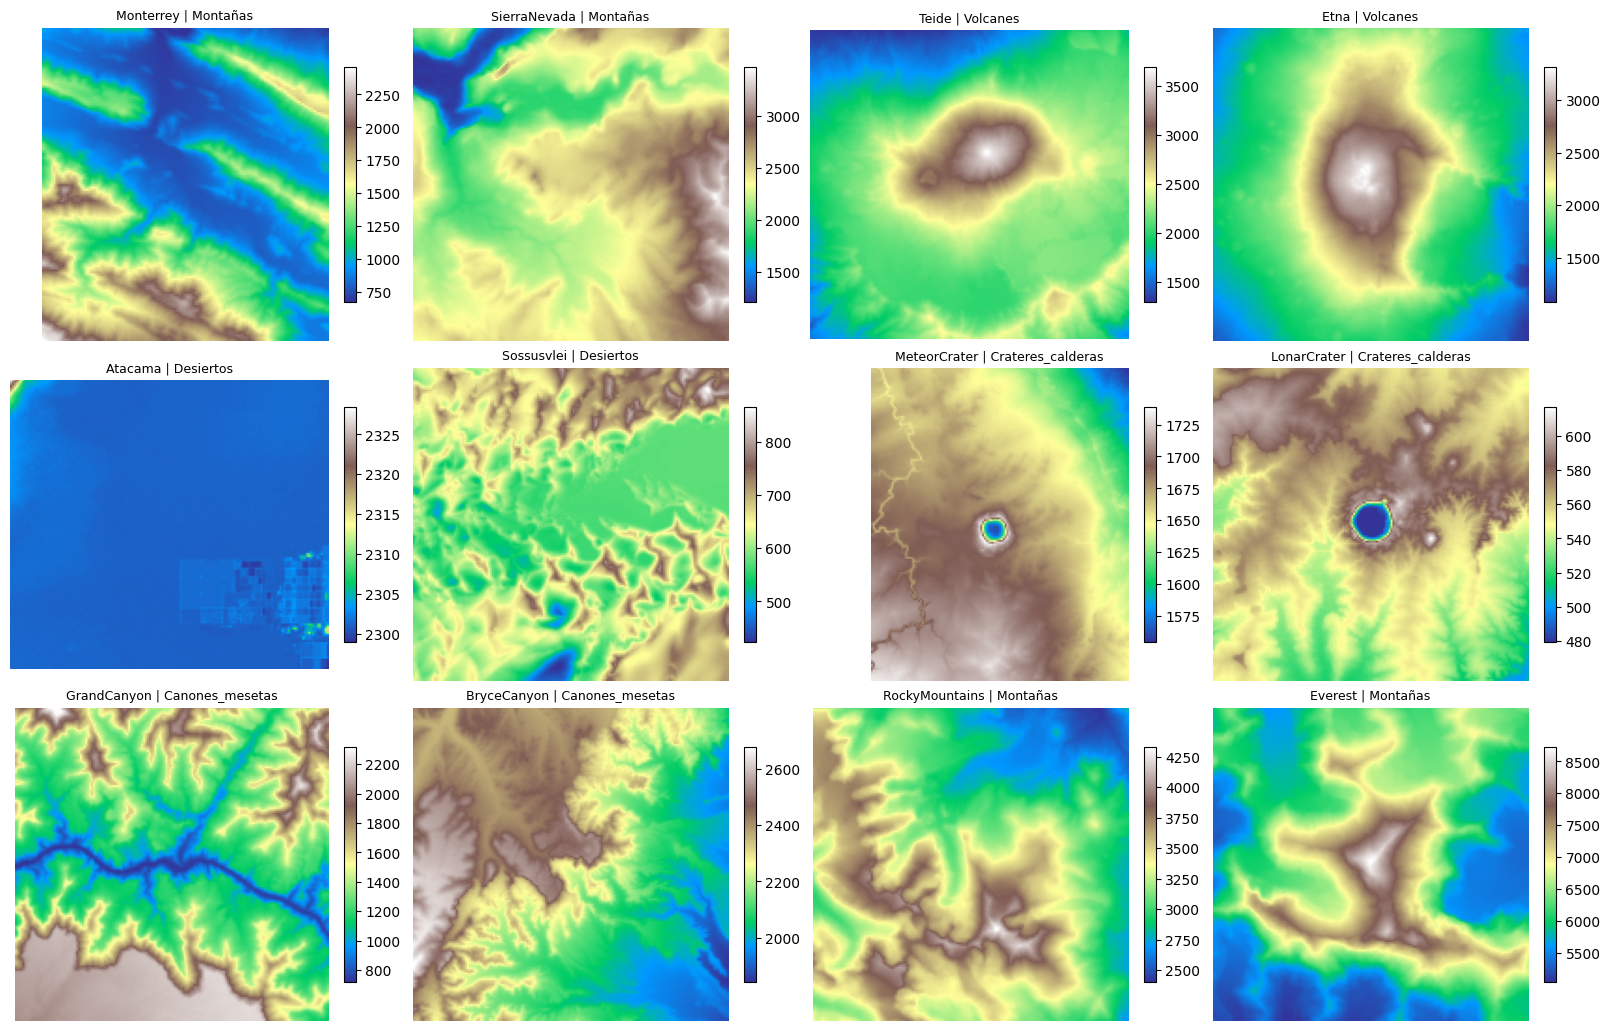

Mostradas 12 de 50 regiones. Todas se procesan igualmente.


In [7]:
# PASO 7 - GALERIA DE HASTA 12 RECORTES TERRESTRES
# Alterna nombres para cubrir varias categorias sin saturar la pantalla
seleccion=[]
for categoria in dict.fromkeys(CATEGORIAS_TERRESTRES.values()):
    seleccion += [nombre for nombre in terrenos_tierra
                  if CATEGORIAS_TERRESTRES[nombre]==categoria][:2]
# Llenar otros huecos sin duplicados (si alguna categoria fallo al descargar)
seleccion += [nombre for nombre in terrenos_tierra if nombre not in seleccion]
seleccion=seleccion[:VISTA_REGIONES]
if seleccion:
    filas=int(np.ceil(len(seleccion)/4))
    fig,axs=plt.subplots(filas,4,figsize=(16,3.4*filas),squeeze=False,constrained_layout=True)
    for ax in axs.ravel(): ax.axis('off')
    for ax,nombre in zip(axs.ravel(),seleccion):
        d=terrenos_tierra[nombre]
        im=ax.imshow(d['H'],cmap='terrain')
        ax.set_title(f'{nombre} | {CATEGORIAS_TERRESTRES[nombre]}',fontsize=9)
        ax.axis('off');fig.colorbar(im,ax=ax,shrink=.75)
    plt.show()
print('Mostradas',len(seleccion),'de',len(terrenos_tierra),'regiones. Todas se procesan igualmente.')


## PASO 8 — URLs oficiales y descarga/lectura AUTOMÁTICA (sin Drive)

**Cambio principal para el equipo:** las rutas ya no apuntan a archivos privados. Se usan las dos URLs públicas de NASA y DLR, exactamente el mismo producto para todos. Primero intentaremos lectura remota de bloques (sin descargar todo). Solo si falla, se descargará el GeoTIFF automáticamente a `/content/`. Si el tamaño supera el límite de seguridad, la celda explica cómo aumentarlo de manera explícita; no se generan datos falsos.

- NASA: https://pgda.gsfc.nasa.gov/products/90
- DLR/ESA: https://hrscteam.dlr.de/public/data/regionaldtms.php


In [8]:
# PASO 8 — CONFIGURACIÓN AUTOMÁTICA DE FUENTES
# No requiere usuario, archivos, contraseña ni Google Drive.

URL_LUNA = 'https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_80MPP_ADJ.TIF'
URL_MARTE = 'https://hrscteam.dlr.de/public/data/HMC30/MC11E/HMC_11E10_da5.tif'

# No usar el archivo completo si funciona la lectura remota por bloques.
INTENTAR_LECTURA_REMOTA = True

# Solo se usa si la lectura remota falla y hay que descargar el archivo entero.
# HRSC puede pesar cientos de MB o varios GB. Se aborta antes de agotarse
# el almacenamiento si el servidor anuncia un tamaño mayor al límite.
MAX_DESCARGA_GB = 5.0

# Guardamos el RECORTE procesado, no el DEM global/regional completo.
BORRAR_COMPLETOS_DESPUES_DE_RECORTE = True

# Opcional: si se necesita ejecutar sin Marte por problemas temporales del
# servidor DLR, cambiar a False y se continuará con Luna, indicando el fallo.
REQUERIR_MARTE = True

print('Fuentes configuradas. No se requiere Google Drive.')
print('Luna: NASA LOLA 80 m/px')
print('Marte: DLR/ESA HRSC DTM da5 50 m/px')


Fuentes configuradas. No se requiere Google Drive.
Luna: NASA LOLA 80 m/px
Marte: DLR/ESA HRSC DTM da5 50 m/px


## PASO 9 — Descargar si hace falta, recortar y validar los DEM planetarios

La función primero intenta **lectura remota por bloques**. Esto funciona especialmente bien con el producto LOLA, que NASA publica como Cloud Optimized GeoTIFF. Para HRSC, el éxito depende de que DLR permita solicitudes parciales y de la organización interna del TIFF; si no funciona, el notebook hace la descarga completa automáticamente. **No simulará** datos si ocurre un error. Al terminar, guarda GeoTIFFs locales pequeños con la resolución común de 80 m/px.

Si Colab se reinicia, basta con ejecutar el notebook de nuevo: se descargan o recuperan los datos para esa sesión.


In [9]:
# PASO 9 — FUNCIONES DE LECTURA REMOTA, DESCARGA Y RECORTE
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from rasterio.windows import Window
from tqdm.auto import tqdm

# Datos del DEM original se leen siempre en unidades físicas correctas.
# NO asignamos EPSG terrestre a archivos planetarios.

def verificar_dem(src, nombre):
    if src.count != 1:
        raise ValueError(f'{nombre}: se necesita DEM de elevacion de 1 banda, no imagen RGB.')
    if src.crs is None or not src.crs.is_projected:
        raise ValueError(f'{nombre}: GeoTIFF sin proyeccion metrico-planetaria reconocible: CRS={src.crs}')
    try:
        unidad, factor = src.crs.linear_units_factor
    except Exception as e:
        raise ValueError(f'{nombre}: no se pudo leer la unidad proyectada del CRS') from e
    if not np.isclose(factor, 1.0, rtol=1e-4):
        raise ValueError(f'{nombre}: sus unidades no son metros ({unidad}; factor={factor}).')
    if abs(src.transform.b)>1e-9 or abs(src.transform.d)>1e-9:
        raise ValueError(f'{nombre}: TIFF rotado. Se requiere remuestreo geoespacial previo.')
    rx,ry=abs(src.transform.a),abs(src.transform.e)
    if max(rx,ry) > RES_M*1.10:
        raise ValueError(f'{nombre}: pixel fuente {rx:.1f}x{ry:.1f} m, demasiado grueso para 80 m. No se inventa detalle.')
    return rx,ry


def leer_recorte_desde_src(src, nombre, lado_m=15000.0):
    rx,ry=verificar_dem(src,nombre)
    cols=min(int(np.ceil(lado_m/rx)),src.width)
    rows=min(int(np.ceil(lado_m/ry)),src.height)
    if cols*rx < TAM_PIX*RES_M or rows*ry < TAM_PIX*RES_M:
        raise ValueError(f'{nombre}: el producto no cubre ni un parche completo.')

    # La primera ventana contiene el centro; otras permiten esquivar NoData.
    posiciones=[(.5,.5),(.25,.25),(.25,.75),(.75,.25),(.75,.75),(.5,.25),(.5,.75)]
    opciones=[]
    for px,py in posiciones:
        c=int((src.width-cols)*px); r=int((src.height-rows)*py)
        w=Window(c,r,cols,rows)
        nx=max(1,int(round(cols*rx/RES_M)))
        ny=max(1,int(round(rows*ry/RES_M)))
        # Remuestreo: promediado sobre un bloque cuando se reduce resolucion.
        H=src.read(1,window=w,out_shape=(ny,nx),masked=True,
                   resampling=Resampling.average).astype('float32').filled(np.nan)
        cobertura=np.isfinite(H).mean()
        if cobertura >= COBERTURA_MIN:
            opciones.append((np.nanstd(H),H,w,cobertura))
    if not opciones:
        raise RuntimeError(f'{nombre}: 7 recortes probados y ninguno supera cobertura {COBERTURA_MIN:.0%}.')

    relieve,H,w,cob=max(opciones,key=lambda a:a[0])
    tr=src.window_transform(w)*rasterio.Affine.scale(w.width/H.shape[1],w.height/H.shape[0])
    dx,dy=abs(tr.a),abs(tr.e)
    if abs(dx-RES_M)>3 or abs(dy-RES_M)>3:
        print(f'ADVERTENCIA: {nombre}, resolucion efectiva {dx:.2f}x{dy:.2f} m')
    salida=SALIDAS/f'{nombre.lower()}_recorte_80m.tif'
    with rasterio.open(salida,'w',driver='GTiff',height=H.shape[0],width=H.shape[1],
                       count=1,dtype='float32',crs=src.crs,transform=tr,
                       nodata=np.nan,compress='deflate') as dst:
        dst.write(H,1)
    return {'nombre':nombre,'cuerpo':nombre,'H':H,'transform':tr,
            'crs':src.crs,'dx':dx,'dy':dy,'ruta':str(salida),
            'cobertura':float(cob),'desv_elevacion':float(relieve)}


def descargar_con_reanudacion(url, destino, max_gb=5.0):
    destino=Path(destino)
    tmp=destino.with_suffix(destino.suffix+'.part')
    if destino.exists():
        try:
            with rasterio.open(destino) as prueba:
                if prueba.count==1:
                    print('Archivo local en cache:',destino)
                    return destino
        except Exception:
            destino.unlink(missing_ok=True)
    sesion=requests.Session()
    retry=Retry(total=3,backoff_factor=1,status_forcelist=[429,500,502,503,504],
                allowed_methods=['GET','HEAD'])
    sesion.mount('https://',HTTPAdapter(max_retries=retry))
    # HEAD es opcional. Algunos servidores no envian Content-Length.
    try:
        h=sesion.head(url,timeout=(15,30),allow_redirects=True)
        if h.ok and h.headers.get('Content-Length'):
            size=int(h.headers['Content-Length'])
            print('Tamaño del DEM remoto:',round(size/1e9,2),'GB')
            if size > max_gb*1e9:
                raise RuntimeError(
                    f'El DEM ocupa {size/1e9:.2f} GB, supera el limite {max_gb} GB. '
                    'Elige un DTM regional mas pequeno o ajusta MAX_DESCARGA_GB con almacenamiento suficiente.'
                )
    except requests.RequestException as ex:
        print('HEAD no disponible; el tamaño se revisara durante la descarga:',str(ex)[:100])

    offset=tmp.stat().st_size if tmp.exists() else 0
    encabezados={'Range':f'bytes={offset}-'} if offset else {}
    with sesion.get(url,stream=True,headers=encabezados,timeout=(20,120),allow_redirects=True) as resp:
        resp.raise_for_status()
        append=bool(offset and resp.status_code==206)
        if not append: offset=0
        n=resp.headers.get('Content-Length')
        total=(offset+int(n)) if n and n.isdigit() else None
        if total is not None and total > max_gb*1e9:
            raise RuntimeError(f'DEM anunciado de {total/1e9:.2f} GB supera {max_gb} GB permitidos.')
        print('Descargando GeoTIFF completo de fuente oficial (puede ser pesado):',url)
        with open(tmp,'ab' if append else 'wb') as f, tqdm(total=total,initial=offset,unit='B',unit_scale=True) as pbar:
            for bloque in resp.iter_content(chunk_size=1024*1024):
                if not bloque: continue
                f.write(bloque);pbar.update(len(bloque))
                if f.tell()>max_gb*1e9:
                    raise RuntimeError(f'Descarga detenida al superar {max_gb} GB; modifica el limite si tienes espacio.')
    tmp.replace(destino)
    return destino


def obtener_planetario_automatico(nombre, url):
    # 1. Preferir lectura por bloques remotos sobre el servidor de NASA o DLR.
    if INTENTAR_LECTURA_REMOTA and url.startswith(('http://','https://')):
        print(f'{nombre}: intentando leer recorte remoto sin descargar el TIFF completo...')
        try:
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',
                              GDAL_HTTP_MAX_RETRY='2',GDAL_HTTP_RETRY_DELAY='1',
                              CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif,.TIF'):
                with rasterio.open('/vsicurl/'+url) as src:
                    result=leer_recorte_desde_src(src,nombre)
            print(f'{nombre}: lectura por bloques OK, recorte local: {result["ruta"]}')
            return result
        except Exception as err:
            print(f'{nombre}: no hubo lectura remota parcial:',str(err)[:250])
            print('Intentaremos la descarga automatica completa como respaldo.')

    # 2. Si el servidor no permite lectura por bloques, bajar archivo original.
    ruta=SALIDAS/f'original_{nombre.lower()}.tif'
    ruta=descargar_con_reanudacion(url,ruta,MAX_DESCARGA_GB)
    try:
        with rasterio.open(ruta) as src:
            result=leer_recorte_desde_src(src,nombre)
    finally:
        if BORRAR_COMPLETOS_DESPUES_DE_RECORTE and ruta.exists():
            ruta.unlink()
            print(nombre,': eliminado TIFF completo, conservamos el recorte procesado')
    return result

print('Funciones de lectura automatica listas.')


Funciones de lectura automatica listas.


## PASO 10 — Obtener automáticamente Luna y Marte, comprobar y visualizar

No se requiere `files.upload()` ni `drive.mount()`. La salida debe mostrar **Luna** y **Marte** si ambos servidores permitieron el acceso. Si no puede obtenerse Marte, se informa el error específico en vez de continuar silenciosamente con datos faltantes.


Luna: intentando leer recorte remoto sin descargar el TIFF completo...
Luna: no hubo lectura remota parcial: Read failed. See previous exception for details.
Intentaremos la descarga automatica completa como respaldo.
Tamaño del DEM remoto: 0.19 GB
Descargando GeoTIFF completo de fuente oficial (puede ser pesado): https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_80MPP_ADJ.TIF


  0%|          | 0.00/189M [00:00<?, ?B/s]

Luna : eliminado TIFF completo, conservamos el recorte procesado
Luna: (188, 188) | dx=80.0 m | dy=80.0 m | validos=100.0%
Marte: intentando leer recorte remoto sin descargar el TIFF completo...
Marte: lectura por bloques OK, recorte local: /content/HackNASA_salidas/marte_recorte_80m.tif
Marte: (188, 188) | dx=79.8 m | dy=79.8 m | validos=100.0%


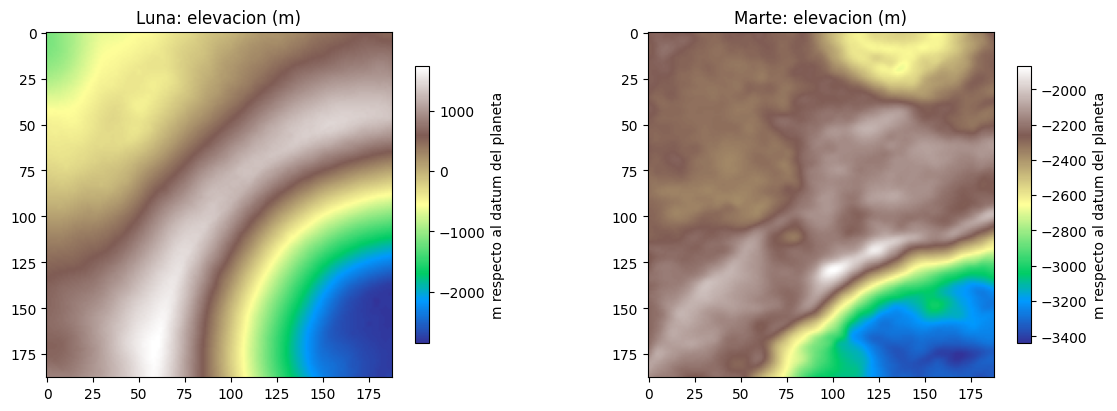

In [10]:
# PASO 10 — CARGA AUTOMATICA DE LUNA Y MARTE
planetas={}
fuentes={'Luna':URL_LUNA,'Marte':URL_MARTE}
errores_planetarios={}

for nombre,url in fuentes.items():
    try:
        planetas[nombre]=obtener_planetario_automatico(nombre,url)
        d=planetas[nombre]
        print(f'{nombre}: {d["H"].shape} | dx={d["dx"]:.1f} m | dy={d["dy"]:.1f} m | validos={d["cobertura"]:.1%}')
    except Exception as exc:
        errores_planetarios[nombre]=str(exc)
        print(f'ERROR DE OBTENCION {nombre}: {exc}')

if not planetas:
    raise RuntimeError('No se pudo leer ninguno de los DEM planetarios desde sus servidores oficiales. '+str(errores_planetarios))
if REQUERIR_MARTE and 'Marte' not in planetas:
    raise RuntimeError('Marte no pudo obtenerse automaticamente. Revisa el error de DLR indicado arriba. '+str(errores_planetarios.get('Marte','')))

fig,axs=plt.subplots(1,len(planetas),figsize=(6*len(planetas),4),squeeze=False,constrained_layout=True)
for ax,(nombre,d) in zip(axs[0],planetas.items()):
    im=ax.imshow(d['H'],cmap='terrain');ax.set_title(f'{nombre}: elevacion (m)')
    fig.colorbar(im,ax=ax,shrink=.8,label='m respecto al datum del planeta')
plt.show()


## PASO 10B — Corregir la escala espacial de Marte (HRSC)

Se conserva el ajuste de proyección que probamos después de la primera ejecución: para el producto HRSC equirectangular con paralelo estándar en 0°, se genera una cuadrícula de 80 m con un paralelo estándar próximo al centro del recorte. **No debe aplicarse dos veces.** Si el CRS no es equirectangular, se avisa sin forzar la corrección. La validez para otros productos de Marte debe comprobarse.

In [11]:
# PASO 10B - AJUSTE LOCAL DE LA ESCALA MARCIANA (HRSC)
# Aplicar antes de derivar pendiente / curvatura / rugosidad.
# Para el DTM HRSC actual se usa una proyeccion equirectangular con radio 3396000m.
if 'Marte' in planetas:
    from rasterio.crs import CRS
    from rasterio.warp import transform_bounds, reproject, Resampling
    from rasterio.transform import array_bounds, from_origin
    marte = planetas['Marte']
    proy = marte['crs'].to_proj4() if marte['crs'] is not None else ''
    if '+proj=eqc' not in proy:
        print('AVISO: Marte no utiliza eqc. Revisar proyeccion antes de usar la correccion local.')
    else:
        # Evitar corregir dos veces si ya se reproyecto antes.
        import re
        coincidencia = re.search(r'\+lat_ts=([-+0-9.]+)', proy)
        lat_ts_actual = float(coincidencia.group(1)) if coincidencia else 0.
        if abs(lat_ts_actual) > 0.01:
            print('Marte ya tiene un paralelo estandar local:',round(lat_ts_actual,4))
        else:
            R_MARTE=3396000.0
            alto,ancho=marte['H'].shape
            xc,yc=marte['transform']*(ancho/2, alto/2)
            lat_centro=float(np.degrees(yc/R_MARTE))
            crs_local=CRS.from_proj4(
                f'+proj=eqc +lat_ts={lat_centro:.10f} +lon_0=0 '
                f'+R={R_MARTE} +units=m +no_defs +type=crs'
            )
            xmin,ymin,xmax,ymax=transform_bounds(
                marte['crs'],crs_local,
                *array_bounds(alto,ancho,marte['transform']),densify_pts=21
            )
            nuevo_ancho=int(np.ceil((xmax-xmin)/RES_M))
            nuevo_alto=int(np.ceil((ymax-ymin)/RES_M))
            nueva_transform=from_origin(xmin,ymax,RES_M,RES_M)
            z_nuevo=np.full((nuevo_alto,nuevo_ancho),np.nan,dtype='float32')
            reproject(
                source=marte['H'].astype('float32'),destination=z_nuevo,
                src_transform=marte['transform'],src_crs=marte['crs'],src_nodata=np.nan,
                dst_transform=nueva_transform,dst_crs=crs_local,dst_nodata=np.nan,
                resampling=Resampling.bilinear
            )
            ruta=SALIDAS/'marte_recorte_80m.tif'
            with rasterio.open(ruta,'w',driver='GTiff',height=nuevo_alto,width=nuevo_ancho,
                              count=1,dtype='float32',crs=crs_local,
                              transform=nueva_transform,nodata=np.nan,compress='deflate') as dst:
                dst.write(z_nuevo,1)
            marte.update({'H':z_nuevo,'transform':nueva_transform,'crs':crs_local,
                          'dx':RES_M,'dy':RES_M,
                          'cobertura':float(np.isfinite(z_nuevo).mean()),'ruta':str(ruta)})
            print('Marte reproyectado:',z_nuevo.shape,'latitud central:',round(lat_centro,4),
                  'cobertura:',round(marte['cobertura']*100,2),'%')
else:
    print('Marte no esta cargado; se omite paso 10B')


Marte reproyectado: (188, 169) latitud central: 26.1876 cobertura: 98.88 %


## PASO 11 — Diagnóstico de resolución y validez planetaria

No comparamos imágenes en colores ni DEMs expresados en grados de latitud.

In [12]:
for nombre,d in planetas.items():
    z=d['H']
    print(nombre, 'malla=',z.shape, 'dx=',round(d['dx'],2),
          'dy=',round(d['dy'],2), 'cobertura=',round(np.isfinite(z).mean()*100,1),'%')
    print('Rango de elevación:',round(np.nanmin(z),2),round(np.nanmax(z),2),'m')
assert planetas, 'Sube al menos un DEM LOLA o HRSC'

Luna malla= (188, 188) dx= 80.0 dy= 80.0 cobertura= 100.0 %
Rango de elevación: -2843.63 1736.76 m
Marte malla= (188, 169) dx= 80.0 dy= 80.0 cobertura= 98.9 %
Rango de elevación: -3434.97 -1870.52 m


## PASO 12 — Construir una pirámide multiescala por terreno

Pirámide grueso → fino; a diferencia del primer DEM de Monterrey, usamos factores 4, 2 y 1 para no perder demasiada información en parches pequeños.

In [13]:
from rasterio.transform import from_origin

def crear_piramide(d, factores=(4,2,1)):
    z=d['H']; salida={}
    for f in factores:
        alto=max(1,int(np.ceil(z.shape[0]/f)))
        ancho=max(1,int(np.ceil(z.shape[1]/f)))
        nuevo=np.full((alto,ancho),np.nan,dtype='float32')
        tr=d['transform']*rasterio.Affine.scale(z.shape[1]/ancho,z.shape[0]/alto)
        reproject(source=z,destination=nuevo,src_transform=d['transform'],src_crs=d['crs'],src_nodata=np.nan,
                  dst_transform=tr,dst_crs=d['crs'],dst_nodata=np.nan,resampling=Resampling.average)
        salida[f]={'H':nuevo,'dx':abs(tr.a),'dy':abs(tr.e),'transform':tr}
    return salida

TERRENOS={**terrenos_tierra,**planetas}
piramides={nombre:crear_piramide(d) for nombre,d in TERRENOS.items()}
for nombre,p in piramides.items():
    print(nombre, {f:(d['H'].shape,round(d['dx'],1)) for f,d in p.items()})

Monterrey {4: ((35, 32), 320.0), 2: ((70, 64), 160.0), 1: ((140, 128), 80.0)}
SierraNevada {4: ((43, 43), 320.0), 2: ((86, 86), 160.0), 1: ((171, 172), 80.0)}
RockyMountains {4: ((42, 43), 314.4), 2: ((84, 85), 159.1), 1: ((168, 169), 80.0)}
Everest {4: ((42, 42), 320.0), 2: ((84, 84), 160.0), 1: ((167, 168), 80.0)}
Matterhorn {4: ((43, 43), 318.1), 2: ((85, 86), 159.1), 1: ((170, 171), 80.0)}
Aconcagua {4: ((42, 43), 314.4), 2: ((84, 85), 159.1), 1: ((168, 169), 80.0)}
CordilleraBlanca {4: ((42, 43), 314.4), 2: ((84, 85), 159.1), 1: ((168, 169), 80.0)}
Drakensberg {4: ((43, 43), 318.1), 2: ((85, 86), 159.1), 1: ((170, 171), 80.0)}
Toubkal {4: ((42, 43), 314.4), 2: ((84, 85), 159.1), 1: ((168, 169), 80.0)}
Elbrus {4: ((43, 44), 314.5), 2: ((86, 87), 159.1), 1: ((172, 173), 80.0)}
Teide {4: ((43, 44), 316.4), 2: ((85, 87), 160.0), 1: ((169, 174), 80.0)}
Etna {4: ((42, 42), 320.0), 2: ((84, 84), 160.0), 1: ((167, 168), 80.0)}
Vesuvio {4: ((42, 43), 314.4), 2: ((84, 85), 159.1), 1: ((168,

## PASO 13 — Visualizar y validar las tres escalas

Una misma área debe mantener la estructura general en todas las escalas.

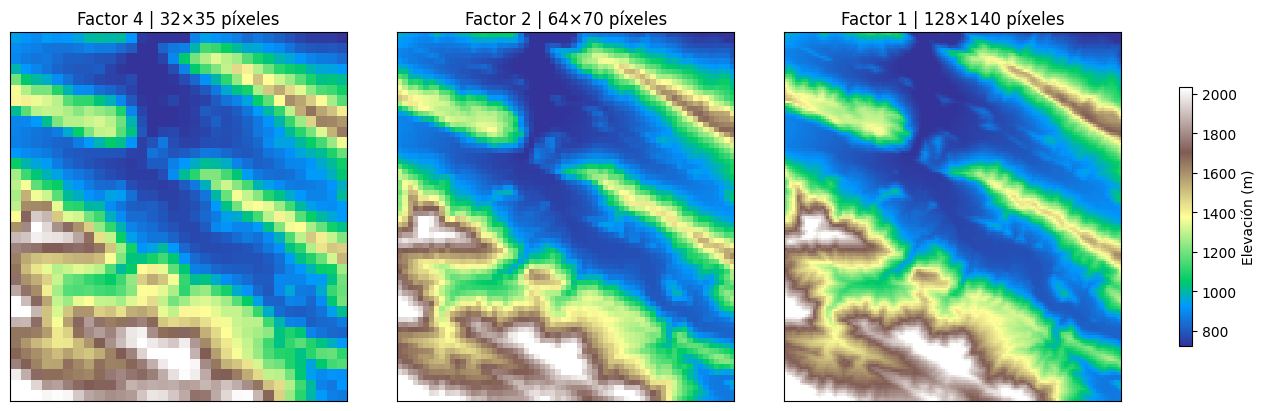

In [14]:
ejemplo_nombre=next(iter(terrenos_tierra))
fig,axs=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
capas=piramides[ejemplo_nombre]
lim=np.nanpercentile(capas[1]['H'],[2,98])
for ax,f in zip(axs,[4,2,1]):
    z=capas[f]['H']
    im=ax.imshow(z,cmap='terrain',vmin=lim[0],vmax=lim[1],interpolation='nearest')
    ax.set_title(f'Factor {f} | {z.shape[1]}×{z.shape[0]} píxeles')
    ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=axs,label='Elevación (m)',shrink=.7)
plt.show()

## PASO 14 — Calcular gradiente, pendiente, curvatura y rugosidad

La pendiente usa derivadas en m/m. La curvatura es un laplaciano aproximado; la rugosidad elimina un plano local.

In [15]:
def caracteristicas_dem(H,dx,dy,ventana=5):
    z=np.asarray(H,dtype='float64')
    valid=np.isfinite(z)
    if not valid.any() or min(z.shape)<ventana: raise ValueError('DEM invalido o demasiado pequeño')
    if not valid.all():
        inds=ndi.distance_transform_edt(~valid,return_indices=True,return_distances=False)
        z0=z[tuple(inds)]
    else: z0=z.copy()
    suave=ndi.gaussian_filter(z0,1,mode='reflect')
    gy,gx=np.gradient(suave,dy,dx)
    g=np.hypot(gx,gy)
    p=np.degrees(np.arctan(g))
    cur=(np.gradient(np.gradient(suave,dx,axis=1),dx,axis=1)
         +np.gradient(np.gradient(suave,dy,axis=0),dy,axis=0))
    r=ventana//2
    yy,xx=np.mgrid[-r:r+1,-r:r+1]
    xx=xx*dx; yy=yy*dy
    n=ventana**2
    vx=np.mean(xx**2); vy=np.mean(yy**2)
    mz=ndi.uniform_filter(z0,ventana,mode='reflect')
    mz2=ndi.uniform_filter(z0*z0,ventana,mode='reflect')
    covx=ndi.correlate(z0,xx/n,mode='reflect')
    covy=ndi.correlate(z0,yy/n,mode='reflect')
    res2=mz2-mz*mz-(covx*covx/vx)-(covy*covy/vy)
    rug=np.sqrt(np.maximum(res2,0))
    cobertura=ndi.uniform_filter(valid.astype(float),ventana,mode='constant',cval=0)
    mascara=cobertura>.999
    for a in (g,p,cur,rug): a[~mascara]=np.nan
    return {'gradiente':g,'pendiente':p,'curvatura':cur,'rugosidad':rug}

## PASO 15 — Probar las fórmulas con un terreno artificial

Comprobación matemática: un plano sin irregularidades debe tener rugosidad cercana a cero.

In [16]:
# Sanidad: un plano inclinado tiene rugosidad casi nula fuera de bordes
Y,X=np.mgrid[:40,:40]
assert np.nanmedian(caracteristicas_dem(1000+X*.8+Y*.4,80,80)['rugosidad'])<1e-3
print('Prueba de plano: OK')

Prueba de plano: OK


## PASO 16 — Calcular características de todos los DEMs

Se reutiliza el mismo algoritmo para Tierra, Luna y Marte.

In [17]:
TERRENOS={**terrenos_tierra,**planetas}
for nombre,d in TERRENOS.items():
    d.update(caracteristicas_dem(d['H'],d['dx'],d['dy']))
    print(nombre,'pendiente mediana:',round(np.nanmedian(d['pendiente']),2),
          '| rugosidad mediana:',round(np.nanmedian(d['rugosidad']),2))

Monterrey pendiente mediana: 21.21 | rugosidad mediana: 16.31
SierraNevada pendiente mediana: 13.32 | rugosidad mediana: 8.61
RockyMountains pendiente mediana: 17.79 | rugosidad mediana: 10.34
Everest pendiente mediana: 34.92 | rugosidad mediana: 16.33
Matterhorn pendiente mediana: 22.28 | rugosidad mediana: 13.73
Aconcagua pendiente mediana: 28.89 | rugosidad mediana: 14.69
CordilleraBlanca pendiente mediana: 27.38 | rugosidad mediana: 14.29
Drakensberg pendiente mediana: 17.2 | rugosidad mediana: 14.16
Toubkal pendiente mediana: 30.23 | rugosidad mediana: 19.58
Elbrus pendiente mediana: 20.09 | rugosidad mediana: 10.33
Teide pendiente mediana: 12.3 | rugosidad mediana: 6.72
Etna pendiente mediana: 11.76 | rugosidad mediana: 4.57
Vesuvio pendiente mediana: 4.06 | rugosidad mediana: 2.15
Fuji pendiente mediana: 12.7 | rugosidad mediana: 4.4
Kilimanjaro pendiente mediana: 14.64 | rugosidad mediana: 7.17
Cotopaxi pendiente mediana: 11.35 | rugosidad mediana: 7.58
Popocatepetl pendiente m

## PASO 17 — Mostrar mapas de pendiente, curvatura y rugosidad

Mapas originales con unidades físicas; no son únicamente imágenes RGB.

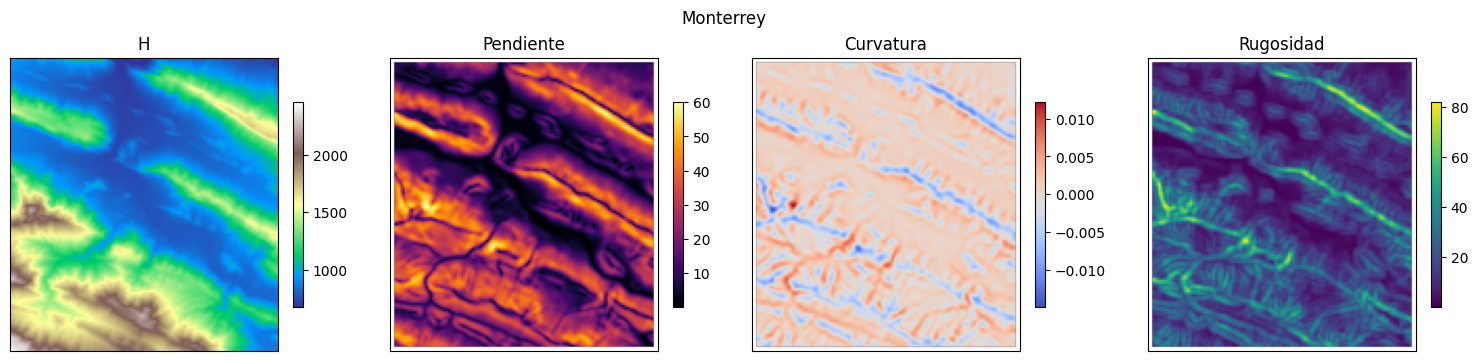

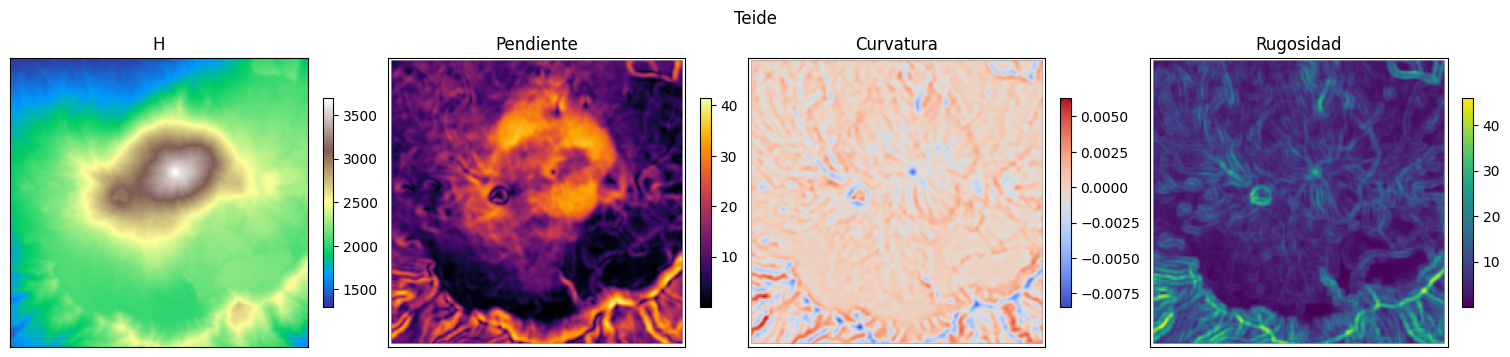

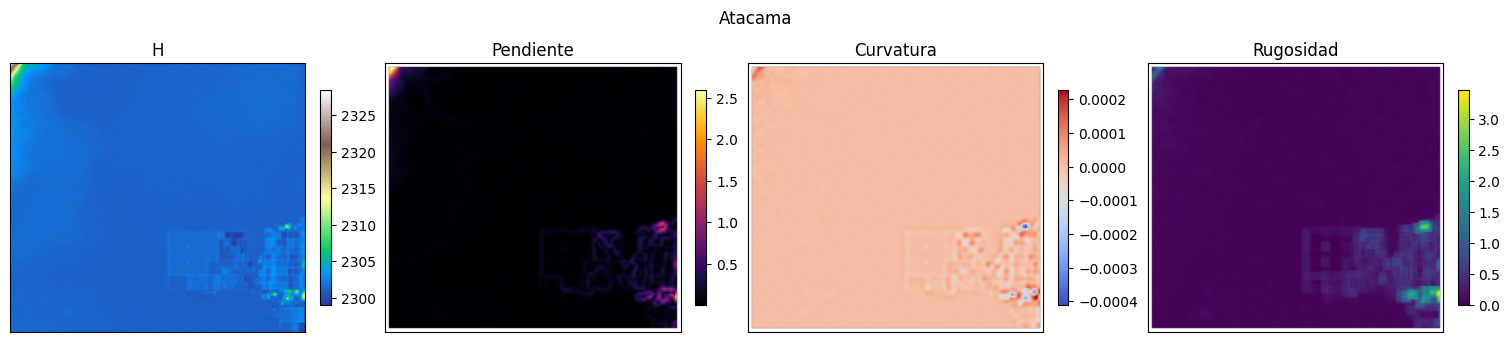

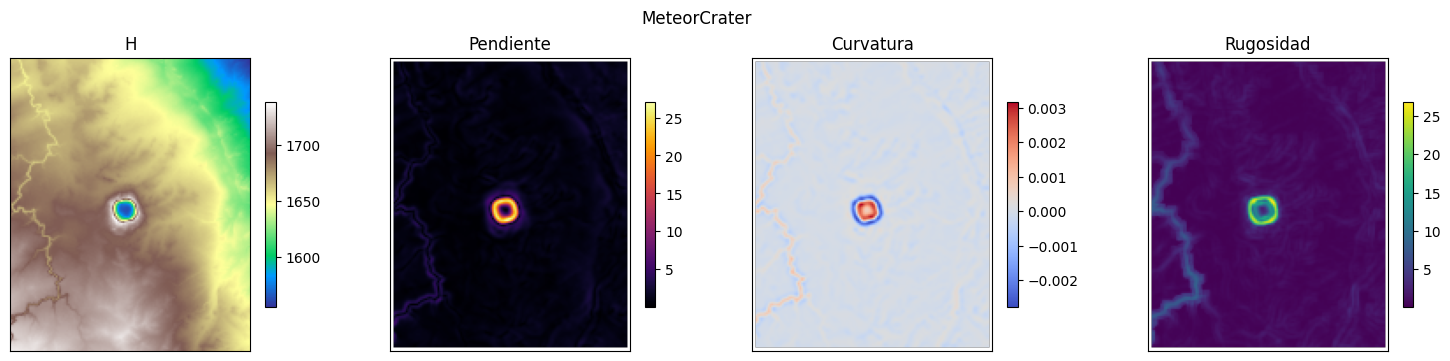

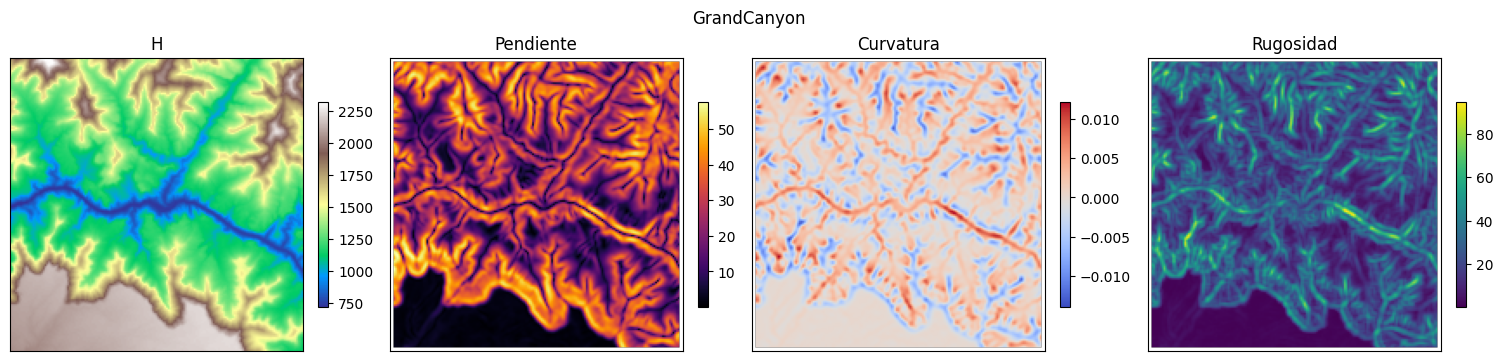

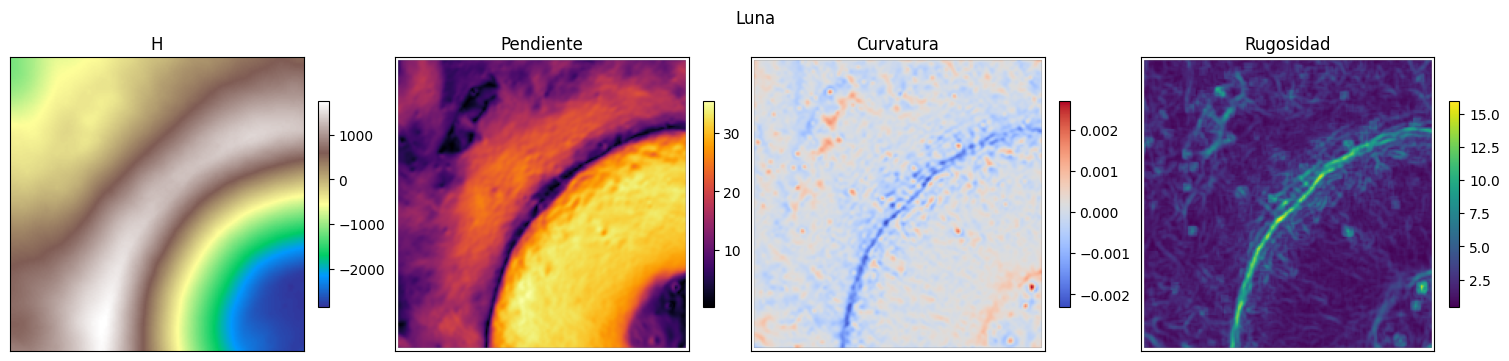

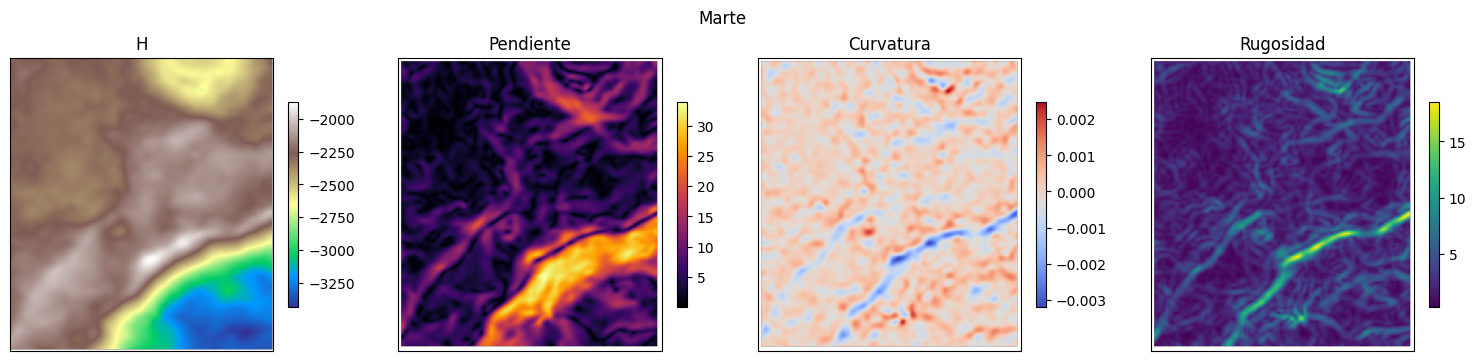

Mapas mostrados: 7 de 52 . Los demas ya estan calculados.


In [18]:
# PASO 17 - MAPAS DE CARACTERISTICAS: MUESTRA, NO 50 FIGURAS
# Calculamos las caracteristicas para TODOS en el paso 16;
# aqui solo visualizamos una muestra para no saturar Colab.
nombres_muestra = []
for categoria in dict.fromkeys(CATEGORIAS_TERRESTRES.values()):
    candidatos = [k for k in terrenos_tierra if CATEGORIAS_TERRESTRES[k]==categoria]
    if candidatos: nombres_muestra.append(candidatos[0])
nombres_muestra += list(planetas)
for nombre in nombres_muestra:
    d=TERRENOS[nombre]
    fig,axs=plt.subplots(1,4,figsize=(15,3.5),constrained_layout=True)
    for ax,key,cmap in zip(axs,['H','pendiente','curvatura','rugosidad'],
                            ['terrain','inferno','coolwarm','viridis']):
        im=ax.imshow(d[key],cmap=cmap)
        ax.set_title(key.capitalize());ax.set_xticks([]);ax.set_yticks([])
        fig.colorbar(im,ax=ax,shrink=.70)
    fig.suptitle(nombre);plt.show()
print('Mapas mostrados:',len(nombres_muestra),'de',len(TERRENOS),'. Los demas ya estan calculados.')


## PASO 18 — Generar máscaras continuas normalizadas

Máscaras normalizadas para visualización por terreno; para comparar físicamente conservaremos los valores sin normalizar.

In [19]:
for nombre,d in TERRENOS.items():
    C=d['curvatura'];R=d['rugosidad'];
    lc=np.nanpercentile(np.abs(C),98); lr=np.nanpercentile(R,98)
    d['curvatura_norm']=np.clip(C/max(lc,1e-12),-1,1)
    d['rugosidad_norm']=np.clip(R/max(lr,1e-12),0,1)
    d['mascara_valida']=np.isfinite(C)&np.isfinite(R)&np.isfinite(d['pendiente'])
    print(nombre,'cobertura util',round(d['mascara_valida'].mean()*100,1),'%')

Monterrey cobertura util 94.1 %
SierraNevada cobertura util 95.4 %
RockyMountains cobertura util 95.3 %
Everest cobertura util 95.3 %
Matterhorn cobertura util 95.4 %
Aconcagua cobertura util 95.3 %
CordilleraBlanca cobertura util 95.3 %
Drakensberg cobertura util 95.4 %
Toubkal cobertura util 95.3 %
Elbrus cobertura util 95.4 %
Teide cobertura util 95.4 %
Etna cobertura util 95.3 %
Vesuvio cobertura util 95.3 %
Fuji cobertura util 95.4 %
Kilimanjaro cobertura util 95.3 %
Cotopaxi cobertura util 95.3 %
Popocatepetl cobertura util 95.3 %
MountStHelens cobertura util 95.3 %
MaunaLoa cobertura util 95.3 %
Bromo cobertura util 95.3 %
Atacama cobertura util 94.6 %
Sossusvlei cobertura util 95.3 %
WhiteDesert cobertura util 95.3 %
KhongorynEls cobertura util 95.4 %
WadiRum cobertura util 95.4 %
RubAlKhali cobertura util 95.3 %
DeathValley cobertura util 95.3 %
KelsoDunes cobertura util 95.3 %
SalarUyuni cobertura util 95.3 %
BadainJaran cobertura util 95.4 %
MeteorCrater cobertura util 94.8 

## PASO 19 — Visualizar las máscaras normalizadas

No usar las máscaras normalizadas individualmente por cuerpo como si fueran unidades físicas equivalentes.

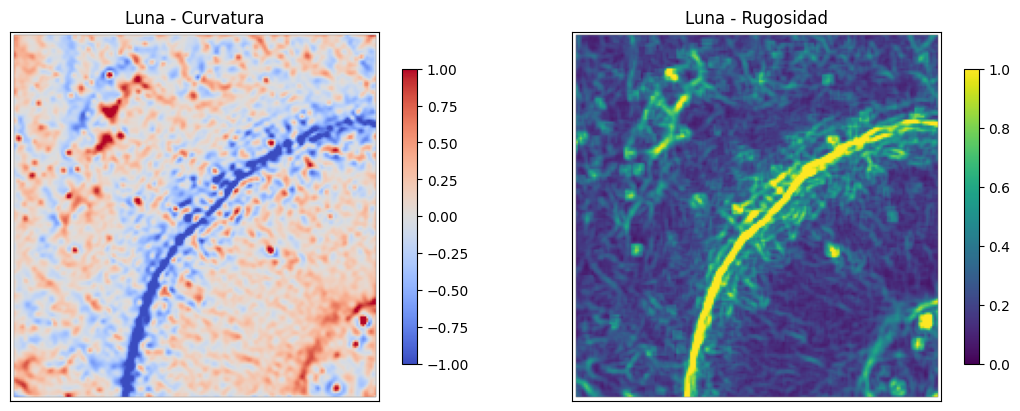

In [20]:
ejemplo=next(iter(planetas))
d=planetas[ejemplo]
fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,z,cmap,titulo,vmin,vmax in [
    (axs[0],d['curvatura_norm'],'coolwarm','Curvatura',-1,1),
    (axs[1],d['rugosidad_norm'],'viridis','Rugosidad',0,1)]:
    im=ax.imshow(z,cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set_title(ejemplo+' - '+titulo); ax.set_xticks([]);ax.set_yticks([])
    fig.colorbar(im,ax=ax,shrink=.8)
plt.show()

## PASO 20 — Definir parches y ocho descriptores por región

Un parche mantiene el mismo tamaño físico a 80 m/píxel, independientemente del planeta.

In [21]:
def crear_parches(d,prefijo,tam_pix=None,salto_pix=None):
    tam_pix = TAM_PIX if tam_pix is None else int(tam_pix)
    salto_pix = SALTO_PIX if salto_pix is None else int(salto_pix)
    registros=[]
    H,P,C,R=(d[k] for k in ('H','pendiente','curvatura','rugosidad'))
    for i in range(0,H.shape[0]-tam_pix+1,salto_pix):
        for j in range(0,H.shape[1]-tam_pix+1,salto_pix):
            s=np.s_[i:i+tam_pix,j:j+tam_pix]
            p,c,r=P[s],C[s],R[s]
            val=np.isfinite(p)&np.isfinite(c)&np.isfinite(r)
            if val.mean()<COBERTURA_MIN: continue
            a=p[val]; b=np.abs(c[val]); z=r[val]
            x,y=d['transform']*(j+tam_pix/2,i+tam_pix/2)
            registros.append({
                'parche_id':f'{prefijo}_{i:03d}_{j:03d}',
                'region':d['nombre'],'cuerpo':d['cuerpo'],
                'fila':i,'col':j,'x':float(x),'y':float(y),
                'crs':str(d['crs']),'cobertura':float(val.mean()),
                'pendiente_media':float(a.mean()),'pendiente_std':float(a.std()),
                'pendiente_p90':float(np.percentile(a,90)),
                'curvatura_abs_media':float(b.mean()),
                'curvatura_abs_p90':float(np.percentile(b,90)),
                'rugosidad_mediana':float(np.median(z)),
                'rugosidad_p90':float(np.percentile(z,90)),
                'rugosidad_std':float(z.std())
            })
    return pd.DataFrame(registros)

## PASO 21 — Extraer vectores de todos los terrenos

Cada fila contiene ID, cuerpo, región, coordenadas, cobertura y ocho rasgos topográficos.

In [22]:
partes=[]
for nombre,d in terrenos_tierra.items():
    t=crear_parches(d,'T_'+nombre)
    print('Tierra',nombre,len(t),'parches')
    if not t.empty: partes.append(t)
if not partes: raise RuntimeError('No hay parches terrestres validos; amplía las zonas')
tabla_tierra=pd.concat(partes,ignore_index=True)
tablas_planeta={nombre:crear_parches(d, 'L' if nombre=='Luna' else 'M') for nombre,d in planetas.items()}
for nombre,t in tablas_planeta.items():
    print(nombre,len(t),'parches')
    if t.empty: raise RuntimeError(f'{nombre} no genero parches; elige otra zona DEM')
display(tabla_tierra[['parche_id','region','pendiente_media','rugosidad_mediana']].head())

Tierra Monterrey 30 parches
Tierra SierraNevada 64 parches
Tierra RockyMountains 49 parches
Tierra Everest 49 parches
Tierra Matterhorn 56 parches
Tierra Aconcagua 49 parches
Tierra CordilleraBlanca 49 parches
Tierra Drakensberg 56 parches
Tierra Toubkal 49 parches
Tierra Elbrus 64 parches
Tierra Teide 56 parches
Tierra Etna 49 parches
Tierra Vesuvio 49 parches
Tierra Fuji 64 parches
Tierra Kilimanjaro 49 parches
Tierra Cotopaxi 49 parches
Tierra Popocatepetl 49 parches
Tierra MountStHelens 49 parches
Tierra MaunaLoa 49 parches
Tierra Bromo 49 parches
Tierra Atacama 42 parches
Tierra Sossusvlei 49 parches
Tierra WhiteDesert 49 parches
Tierra KhongorynEls 64 parches
Tierra WadiRum 56 parches
Tierra RubAlKhali 49 parches
Tierra DeathValley 49 parches
Tierra KelsoDunes 49 parches
Tierra SalarUyuni 49 parches
Tierra BadainJaran 64 parches
Tierra MeteorCrater 42 parches
Tierra LonarCrater 49 parches
Tierra WolfeCreekCrater 49 parches
Tierra RoterKamm 49 parches
Tierra RiesCrater 64 parches


,parche_id,region,pendiente_media,rugosidad_mediana
0,T_Monterrey_000_000,Monterrey,19.280768,14.501092
1,T_Monterrey_000_019,Monterrey,15.699038,10.991833
2,T_Monterrey_000_038,Monterrey,14.876353,10.312038
3,T_Monterrey_000_057,Monterrey,20.311575,13.228612
4,T_Monterrey_000_076,Monterrey,26.014498,12.560504


## PASO 22 — Validar parches, cobertura y coordenadas

Comprueba que los parches corresponden a zonas reales y tienen cobertura suficiente.

Tierra parches: 2579 cobertura media: 0.983
Primeros IDs: ['T_Monterrey_000_000', 'T_Monterrey_000_019', 'T_Monterrey_000_038']
Luna parches: 64 cobertura media: 0.987
Primeros IDs: ['L_000_000', 'L_000_019', 'L_000_038']
Marte parches: 56 cobertura media: 0.986
Primeros IDs: ['M_000_000', 'M_000_019', 'M_000_038']


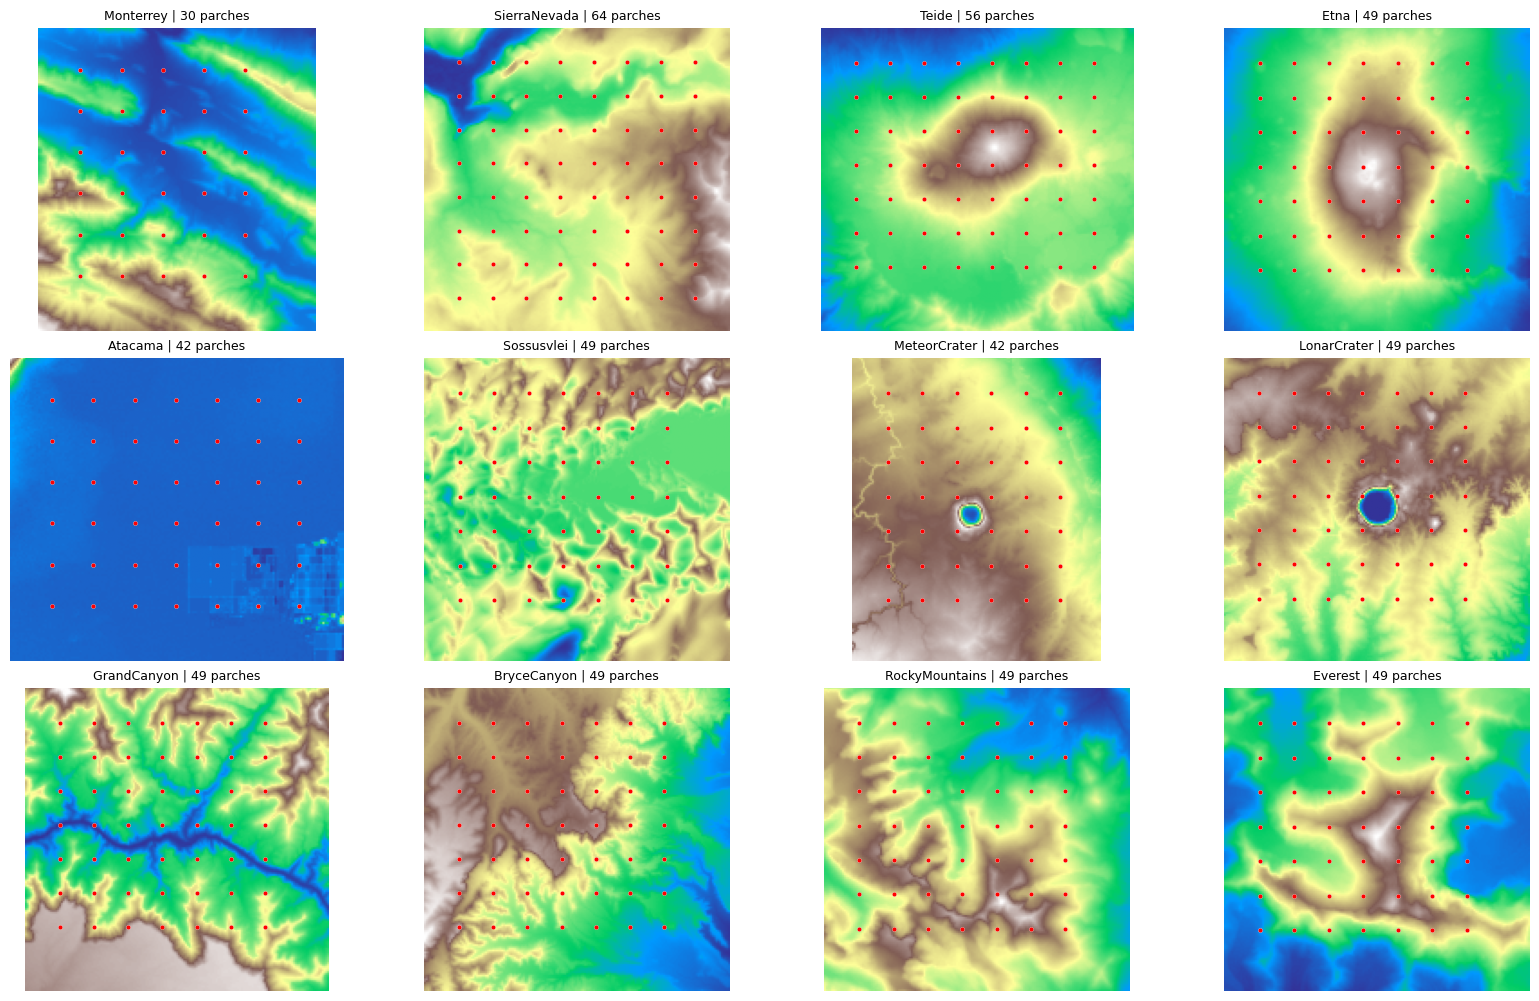

Se muestran 12 regiones; se procesaron todas.


In [23]:
# PASO 22 - VALIDACION DE PARCHES Y GALERIA DE 12 REGIONeS
for cuerpo, tabla in [('Tierra',tabla_tierra),*list(tablas_planeta.items())]:
    print(cuerpo,'parches:',len(tabla), 'cobertura media:', round(tabla['cobertura'].mean(),3))
    print('Primeros IDs:', tabla['parche_id'].head(3).tolist())

muestra_regiones=seleccion[:VISTA_REGIONES]
filas=int(np.ceil(len(muestra_regiones)/4))
fig,axs=plt.subplots(filas,4,figsize=(16,filas*3.3),squeeze=False,constrained_layout=True)
for ax in axs.ravel():ax.axis('off')
for ax,nombre in zip(axs.ravel(),muestra_regiones):
    d=terrenos_tierra[nombre]
    ax.imshow(d['H'],cmap='terrain')
    t=tabla_tierra[tabla_tierra['region']==nombre]
    ax.scatter(t['col']+TAM_PIX/2,t['fila']+TAM_PIX/2,s=10,c='red',edgecolors='white',linewidths=.2)
    ax.set_title(f'{nombre} | {len(t)} parches',fontsize=9)
    ax.axis('off')
plt.show()
print('Se muestran',len(muestra_regiones),'regiones; se procesaron todas.')


## PASO 23 — Normalización común y pesos físicos iniciales

Se calculan la mediana y el IQR SOLO en la base terrestre y se aplican a ambos planetas; los pesos por familia suman 1.

In [24]:
mediana=tabla_tierra[CARACTERISTICAS].median()
q25=tabla_tierra[CARACTERISTICAS].quantile(.25)
q75=tabla_tierra[CARACTERISTICAS].quantile(.75)
escala=(q75-q25).where((q75-q25)>1e-12,1.0)
X_tierra=(tabla_tierra[CARACTERISTICAS]-mediana)/escala
X_planeta={nombre:(t[CARACTERISTICAS]-mediana)/escala for nombre,t in tablas_planeta.items()}
# Igual peso total por familia: pendiente (3), curvatura (2), rugosidad (3)
pesos=pd.Series([1/9]*3+[1/6]*2+[1/9]*3,index=CARACTERISTICAS)
print('Base terrestre:',len(X_tierra),'vectores')
for n,x in X_planeta.items(): print(n,len(x),'vectores')

Base terrestre: 2579 vectores
Luna 64 vectores
Marte 56 vectores


## PASO 24 — Primer ranking físico contra Tierra

Ranking usando únicamente pendiente/curvatura/rugosidad, sin considerar todavía cómo se organizan espacialmente.

In [25]:
rankings_fisicos={}
referencias={}
for nombre,t in tablas_planeta.items():
    idx=(t['pendiente_media']-t['pendiente_media'].median()).abs().idxmin()
    referencias[nombre]=idx
    delta=X_tierra.sub(X_planeta[nombre].loc[idx],axis=1).pow(2)
    dist=delta.mul(pesos,axis=1).sum(axis=1)/pesos.sum()
    ranking=tabla_tierra[['parche_id','region','fila','col']].copy()
    ranking['distancia_fisica']=dist.to_numpy()
    ranking=ranking.sort_values('distancia_fisica').reset_index(drop=True)
    rankings_fisicos[nombre]=ranking
    print(nombre,'referencia:',t.loc[idx,'parche_id'])
    display(ranking.head(5).round(4))

Luna referencia: L_038_095


,parche_id,region,fila,col,distancia_fisica
0,T_Etna_095_038,Etna,95,38,0.0093
1,T_Etna_019_038,Etna,19,38,0.0097
2,T_Fuji_038_019,Fuji,38,19,0.0098
3,T_Fuji_095_019,Fuji,95,19,0.0103
4,T_Fuji_076_114,Fuji,76,114,0.0109


Marte referencia: M_114_019


,parche_id,region,fila,col,distancia_fisica
0,T_NewberryCaldera_000_000,NewberryCaldera,0,0,0.0016
1,T_Vesuvio_095_019,Vesuvio,95,19,0.0022
2,T_TibetanPlateau_038_019,TibetanPlateau,38,19,0.0032
3,T_NewberryCaldera_038_000,NewberryCaldera,38,0,0.0037
4,T_Vesuvio_114_057,Vesuvio,114,57,0.0037


## PASO 25 — Analizar contribuciones de las ocho características

Diagnóstico para comprender qué variables alejan o acercan cada par de terrenos.

,pendiente_media,pendiente_std,pendiente_p90,curvatura_abs_media,curvatura_abs_p90,rugosidad_mediana,rugosidad_p90,rugosidad_std
parche_id,,,,,,,,
T_Etna_019_038,0.0032,0.0006,0.0000,0.0018,0.0007,0.0028,0.0006,0.0000
T_Etna_095_038,0.0009,0.0071,0.0000,0.0001,0.0000,0.0007,0.0000,0.0004
T_Fuji_038_019,0.0031,0.0037,0.0002,0.0002,0.0000,0.0022,0.0000,0.0003


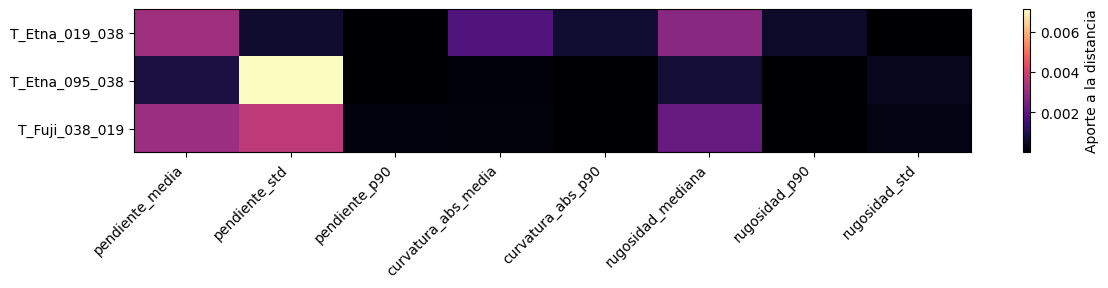

In [26]:
nombre=next(iter(planetas)); idx=referencias[nombre]
seleccion=rankings_fisicos[nombre].head(3)
indices=tabla_tierra.index[tabla_tierra['parche_id'].isin(seleccion['parche_id'])]
contr=((X_tierra.loc[indices].sub(X_planeta[nombre].loc[idx],axis=1).pow(2))
       .mul(pesos,axis=1)/pesos.sum())
contr.index=tabla_tierra.loc[indices,'parche_id']
display(contr.round(4))
fig,ax=plt.subplots(figsize=(12,3))
im=ax.imshow(contr.values,cmap='magma',aspect='auto')
ax.set_xticks(range(len(CARACTERISTICAS)));ax.set_xticklabels(CARACTERISTICAS,rotation=45,ha='right')
ax.set_yticks(range(len(contr)));ax.set_yticklabels(contr.index)
fig.colorbar(im,ax=ax,label='Aporte a la distancia');plt.tight_layout();plt.show()

## PASO 26 — Extraer parches para comparación espacial

Convierte filas de la tabla en pequeños mapas de elevación reales.

In [27]:
def parche(fila):
    d=TERRENOS[fila['region']]
    i,j=int(fila['fila']),int(fila['col'])
    return d['H'][i:i+TAM_PIX,j:j+TAM_PIX]

## PASO 27 — Eliminar la inclinación general (detrending)

Ajustamos un plano por mínimos cuadrados y lo restamos antes de comparar patrones locales.

In [28]:
def sin_plano(z):
    z=np.asarray(z,dtype=float); v=np.isfinite(z)
    if v.mean()<COBERTURA_MIN: return None
    yy,xx=np.indices(z.shape)
    A=np.column_stack([xx[v],yy[v],np.ones(v.sum())])
    a,b,c=np.linalg.lstsq(A,z[v],rcond=None)[0]
    ret=z-(a*xx+b*yy+c); ret[~v]=np.nan
    return ret

## PASO 28 — Comparar formas con rotaciones de 0°, 90°, 180° y 270°

Correlación normalizada sobre elevación residual; no confundir correlación con porcentaje de similitud.

In [29]:
def corr_forma(z1,z2):
    a,b=sin_plano(z1),sin_plano(z2)
    if a is None or b is None: return np.nan,np.nan
    def suav(z):
        v=np.isfinite(z)
        num=ndi.gaussian_filter(np.where(v,z,0),1)
        den=ndi.gaussian_filter(v.astype(float),1)
        zz=num/np.maximum(den,1e-12); zz[~v]=np.nan
        return zz
    a,b=suav(a),suav(b)
    mejor=(-np.inf,np.nan)
    for k in range(4):
        rot=np.rot90(b,k)
        v=np.isfinite(a)&np.isfinite(rot)
        if v.mean()<COBERTURA_MIN: continue
        aa=a[v]-a[v].mean(); bb=rot[v]-rot[v].mean()
        den=np.linalg.norm(aa)*np.linalg.norm(bb)
        if den<1e-12: continue
        rho=float(np.dot(aa,bb)/den)
        if rho>mejor[0]: mejor=(rho,k*90)
    return mejor if np.isfinite(mejor[0]) else (np.nan,np.nan)

## PASO 29 — Contrastar rankings físicos y geométricos

Este paso reproduce la comparación estadística frente a comparación de formas del proyecto anterior.

In [30]:
# PASO 29 - CONTRASTE EXPLORATORIO FISICO VS GEOMETRICO
# Para 50 regiones se evalua geometria en un subconjunto de candidatos
# preseleccionados fisicamente; NO se afirma que sea un ranking geometrico global.
comparaciones_independientes={}
for nombre,t in tablas_planeta.items():
    idx=referencias[nombre]
    Href=parche(t.loc[idx])
    n_evaluar=CANDIDATOS_GEOM if CANDIDATOS_GEOM is not None else len(tabla_tierra)
    ids=rankings_fisicos[nombre].head(n_evaluar)['parche_id']
    subset=tabla_tierra[tabla_tierra['parche_id'].isin(ids)].copy()
    filas=[]
    for _,f in subset.iterrows():
        r,ang=corr_forma(Href,parche(f))
        filas.append({'parche_id':f['parche_id'],'region':f['region'],
                      'corr_forma':r,'rotacion_grados':ang})
    df=pd.DataFrame(filas)
    fis=rankings_fisicos[nombre][['parche_id','distancia_fisica']]
    comparaciones_independientes[nombre]=df.merge(fis,on='parche_id')
    print('\n',nombre,'candidatos geometricos evaluados:',len(df),'de',len(tabla_tierra))
    print('TOP fisico (global):')
    display(rankings_fisicos[nombre].head(5).round(4))
    print('TOP geometrico (SOLO entre preseleccionados por distancia fisica):')
    display(comparaciones_independientes[nombre].nlargest(5,'corr_forma').round(4))



 Luna candidatos geometricos evaluados: 80 de 2579
TOP fisico (global):


,parche_id,region,fila,col,distancia_fisica
0,T_Etna_095_038,Etna,95,38,0.0093
1,T_Etna_019_038,Etna,19,38,0.0097
2,T_Fuji_038_019,Fuji,38,19,0.0098
3,T_Fuji_095_019,Fuji,95,19,0.0103
4,T_Fuji_076_114,Fuji,76,114,0.0109


TOP geometrico (SOLO entre preseleccionados por distancia fisica):


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
41,T_Fuji_019_038,Fuji,0.8668,90,0.0401
12,T_Etna_000_076,Etna,0.8655,0,0.0427
45,T_Fuji_038_038,Fuji,0.8570,270,0.0113
46,T_Fuji_038_057,Fuji,0.8506,90,0.0364
31,T_Etna_114_057,Etna,0.8202,0,0.0295



 Marte candidatos geometricos evaluados: 80 de 2579
TOP fisico (global):


,parche_id,region,fila,col,distancia_fisica
0,T_NewberryCaldera_000_000,NewberryCaldera,0,0,0.0016
1,T_Vesuvio_095_019,Vesuvio,95,19,0.0022
2,T_TibetanPlateau_038_019,TibetanPlateau,38,19,0.0032
3,T_NewberryCaldera_038_000,NewberryCaldera,38,0,0.0037
4,T_Vesuvio_114_057,Vesuvio,114,57,0.0037


TOP geometrico (SOLO entre preseleccionados por distancia fisica):


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
28,T_MaunaLoa_114_114,MaunaLoa,0.7754,180,0.0124
38,T_KelsoDunes_057_019,KelsoDunes,0.7249,180,0.0052
14,T_Vesuvio_114_038,Vesuvio,0.6988,0,0.0099
21,T_Kilimanjaro_000_000,Kilimanjaro,0.6818,270,0.0069
24,T_MaunaLoa_038_095,MaunaLoa,0.6470,180,0.0076


## PASO 30 — Construir el score combinado con pesos configurables

Normaliza posiciones de ambos rankings a [0,1] y combina los dos criterios.

In [31]:
def combinar(df,peso_fisico=PESO_FISICO):
    d=df.replace([np.inf,-np.inf],np.nan).dropna(subset=['distancia_fisica','corr_forma']).copy()
    if len(d)<2: raise ValueError('No hay suficientes candidatos comparables')
    n=len(d)
    d['rango_fisico']=(d['distancia_fisica'].rank(ascending=True)-1)/(n-1)
    d['rango_forma']=(d['corr_forma'].rank(ascending=False)-1)/(n-1)
    d['score_final']=peso_fisico*d['rango_fisico']+(1-peso_fisico)*d['rango_forma']
    return d.sort_values(['score_final','distancia_fisica','parche_id']).reset_index(drop=True)

def buscar(nombre, indice_ref):
    ref=tablas_planeta[nombre].loc[indice_ref]
    zref=parche(ref)
    dif=(X_tierra.sub(X_planeta[nombre].loc[indice_ref],axis=1))**2
    df=tabla_tierra[['parche_id','region','fila','col','x','y']].copy()
    df['distancia_fisica']=(dif.mul(pesos,axis=1).sum(axis=1)/pesos.sum()).to_numpy()
    if CANDIDATOS_GEOM is not None:
        df=df.nsmallest(CANDIDATOS_GEOM,'distancia_fisica').copy()
    corr=[corr_forma(zref,parche(f)) for _,f in df.iterrows()]
    df['corr_forma']=[v[0] for v in corr]
    df['rotacion_grados']=[v[1] for v in corr]
    return combinar(df), df

## PASO 31 — Obtener rankings combinados Luna–Tierra y Marte–Tierra

Aquí se integra la búsqueda física con la comparación de formas, sin mezclar coordenadas de otros planetas.

In [32]:
rankings={};metricas={}
for nombre,t in tablas_planeta.items():
    idx=referencias[nombre]
    rankings[nombre],metricas[nombre]=buscar(nombre,idx)
    print('Referencia:',nombre,t.loc[idx,'parche_id'])
    display(rankings[nombre][['parche_id','region','distancia_fisica','corr_forma','score_final']].head(10).round(4))

Referencia: Luna L_038_095


,parche_id,region,distancia_fisica,corr_forma,score_final
0,T_Fuji_038_038,Fuji,0.0113,0.8570,0.0443
1,T_Etna_076_038,Etna,0.0122,0.7888,0.0949
2,T_Etna_095_038,Etna,0.0093,0.6607,0.1392
3,T_Fuji_095_114,Fuji,0.0118,0.6860,0.1646
4,T_Etna_019_038,Etna,0.0097,0.6102,0.1962
5,T_Etna_038_038,Etna,0.0220,0.7488,0.2025
6,T_Fuji_095_038,Fuji,0.0217,0.7019,0.2278
7,T_Fuji_095_019,Fuji,0.0103,0.5757,0.2532
8,T_Etna_114_057,Etna,0.0295,0.8202,0.2532
9,T_Fuji_019_057,Fuji,0.0219,0.6368,0.2975


Referencia: Marte M_114_019


,parche_id,region,distancia_fisica,corr_forma,score_final
0,T_KelsoDunes_057_019,KelsoDunes,0.0052,0.7249,0.0506
1,T_Yellowstone_019_057,Yellowstone,0.0061,0.6343,0.0886
2,T_Kilimanjaro_000_000,Kilimanjaro,0.0069,0.6818,0.0949
3,T_MaunaLoa_038_095,MaunaLoa,0.0076,0.6470,0.1266
4,T_TibetanPlateau_038_038,TibetanPlateau,0.0066,0.5513,0.1456
5,T_Vesuvio_076_019,Vesuvio,0.0073,0.6171,0.1519
6,T_NewberryCaldera_038_000,NewberryCaldera,0.0037,0.4534,0.2025
7,T_Yellowstone_038_114,Yellowstone,0.0082,0.5313,0.2278
8,T_RoterKamm_076_057,RoterKamm,0.0088,0.5497,0.2468
9,T_Vesuvio_095_019,Vesuvio,0.0022,0.3333,0.2468


## PASO 32 — Visualizar el Top 5 combinado y sus rotaciones

Dos terrenos parecidos en su score no necesariamente son equivalentes geológicamente.

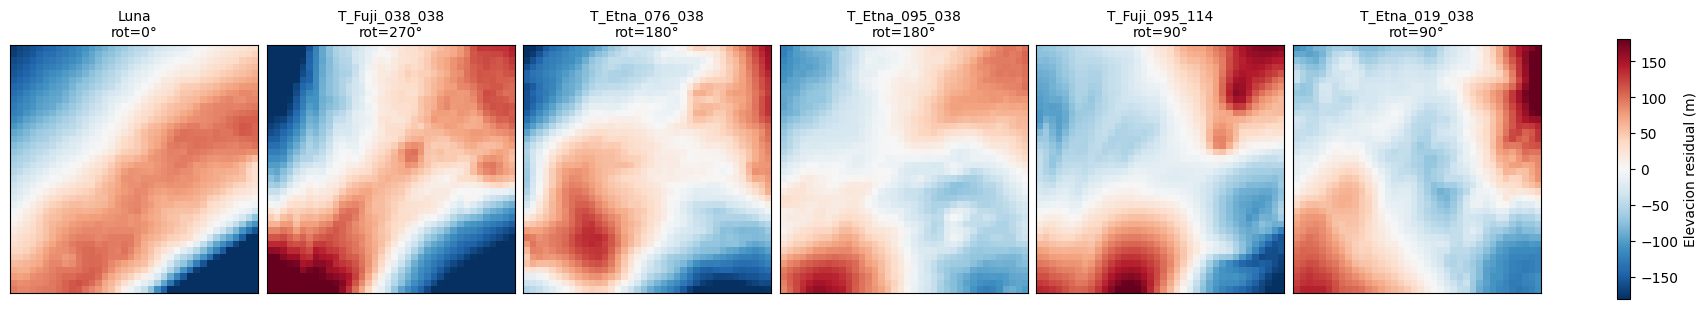

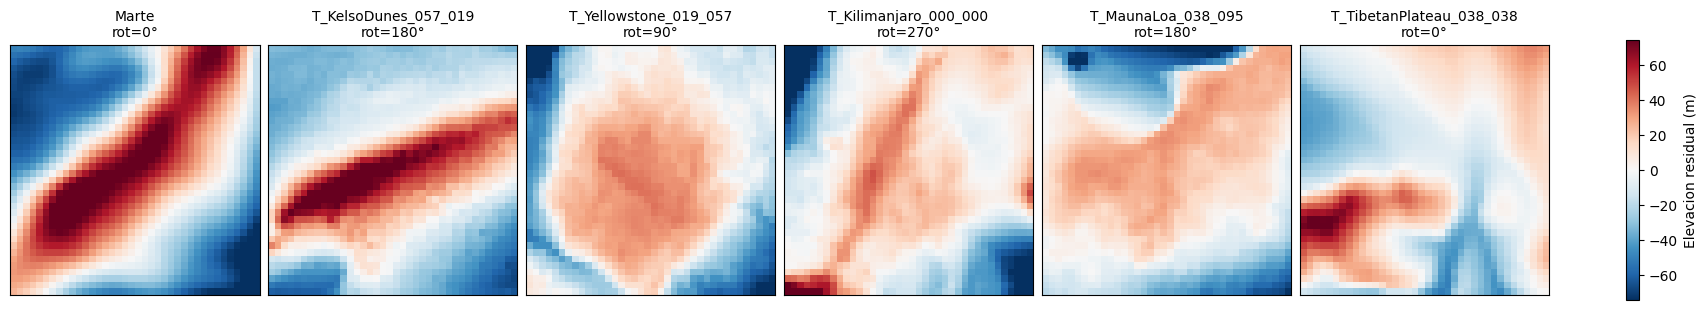

In [33]:
def visualizar(nombre):
    indice=referencias[nombre]
    ref=tablas_planeta[nombre].loc[indice]
    lista=[(nombre,ref,0)]
    porid=tabla_tierra.set_index('parche_id')
    for _,f in rankings[nombre].head(5).iterrows():
        lista.append((f['parche_id'],porid.loc[f['parche_id']],int(f['rotacion_grados'])))
    imgs=[]
    for lab,f,ang in lista:
        zz=sin_plano(parche(f))
        imgs.append(np.rot90(zz,(ang//90)%4))
    vals=np.concatenate([z[np.isfinite(z)] for z in imgs])
    lim=max(float(np.nanpercentile(np.abs(vals),97)),1e-6)
    fig,axs=plt.subplots(1,len(imgs),figsize=(17,3.8),constrained_layout=True)
    for ax,z,(lab,_,ang) in zip(axs,imgs,lista):
        im=ax.imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim)
        ax.set_title(f'{lab}\nrot={ang}°',fontsize=10)
        ax.set_xticks([]);ax.set_yticks([])
    fig.colorbar(im,ax=axs,shrink=.7,label='Elevacion residual (m)')
    fig.savefig(SALIDAS/f'top5_{nombre.lower()}.png',dpi=150,bbox_inches='tight')
    plt.show()

for nombre in rankings: visualizar(nombre)

## PASO 33 — Elegir hasta ocho referencias no superpuestas por planeta y ejecutar búsquedas

Repite la búsqueda para distintas pendientes, no solo para una referencia lunar.

In [34]:
pesos_prueba=[0,.25,.5,.75,1.]
registros=[]; sensibilidad=[]; detalle=[]
for nombre,t in tablas_planeta.items():
    orden=t['pendiente_media'].sort_values().index.to_list()
    elegidos=[referencias[nombre]]
    objetivos=np.linspace(0,len(orden)-1,min(16,len(orden)),dtype=int)
    for pos in objetivos:
        idx=orden[pos]
        f=t.loc[idx]
        if all(not(abs(f['fila']-t.loc[j,'fila'])<TAM_PIX and
                   abs(f['col']-t.loc[j,'col'])<TAM_PIX) for j in elegidos):
            elegidos.append(idx)
        if len(elegidos)>=8:break
    for idx in elegidos:
        base,df=buscar(nombre,idx)
        identificador=t.loc[idx,'parche_id']
        primero=base.iloc[0]
        registros.append({'cuerpo':nombre,'referencia':identificador,
            'mejor_tierra':primero['parche_id'],'region':primero['region'],
            'score_final':primero['score_final'],
            'distancia_fisica':primero['distancia_fisica'],
            'corr_forma':primero['corr_forma']})
        copia=base.copy();copia['cuerpo']=nombre;copia['referencia']=identificador
        detalle.append(copia)
        top_base=set(base.head(3)['parche_id'])
        for peso in pesos_prueba:
            otra=combinar(df,peso)
            top=set(otra.head(3)['parche_id'])
            sensibilidad.append({'cuerpo':nombre,'referencia':identificador,
                'peso_fisico':peso,'mismo_top1':int(otra.iloc[0]['parche_id']==primero['parche_id']),
                'jaccard_top3':len(top&top_base)/len(top|top_base)})

## PASO 34 — Resumir los rankings multilunares y multimarcianos

Compara el resultado más cercano por referencia; no interpretes los scores normalizados como porcentajes de exactitud.

In [35]:
resumen=pd.DataFrame(registros)
tabla_sens=pd.DataFrame(sensibilidad)
tabla_detalle=pd.concat(detalle,ignore_index=True)
display(resumen.round(4))
estabilidad=tabla_sens.groupby(['cuerpo','peso_fisico'])[['mismo_top1','jaccard_top3']].mean()*100
print('Sensibilidad contra pesos 50/50 (no exactitud):')
display(estabilidad.round(1))

,cuerpo,referencia,mejor_tierra,region,score_final,distancia_fisica,corr_forma
0,Luna,L_038_095,T_Fuji_038_038,Fuji,0.0443,0.0113,0.8570
1,Luna,L_038_000,T_Vesuvio_114_076,Vesuvio,0.0380,0.0016,0.6236
2,Luna,L_000_057,T_Fuji_000_114,Fuji,0.0253,0.0074,0.7568
3,Luna,L_000_095,T_Etna_095_038,Etna,0.0443,0.0143,0.8319
4,Luna,L_038_038,T_Teide_095_038,Teide,0.0443,0.0198,0.8898
5,Luna,L_133_038,T_Etna_038_057,Etna,0.0063,0.0114,0.8233
6,Luna,L_095_057,T_Popocatepetl_038_076,Popocatepetl,0.0886,0.0193,0.8577
7,Luna,L_133_133,T_Etna_038_019,Etna,0.0696,0.0650,0.8491
8,Marte,M_114_019,T_KelsoDunes_057_019,KelsoDunes,0.0506,0.0052,0.7249
9,Marte,M_019_000,T_LonarCrater_038_000,LonarCrater,0.0316,0.0005,0.6417


Sensibilidad contra pesos 50/50 (no exactitud):


mismo_top1  jaccard_top3
cuerpo peso_fisico                          
Luna   0.00               12.5          28.7
       0.25               75.0          75.0
       0.50              100.0         100.0
       0.75               75.0          61.3
       1.00               12.5          15.0
Marte  0.00                0.0          20.0
       0.25               50.0          58.8
       0.50              100.0         100.0
       0.75               62.5          56.2
       1.00               12.5          10.0

## PASO 35 — Visualizar sensibilidad de rankings a pesos

La coincidencia 100% en 50/50 es trivial: es el mismo ranking comparado consigo mismo.

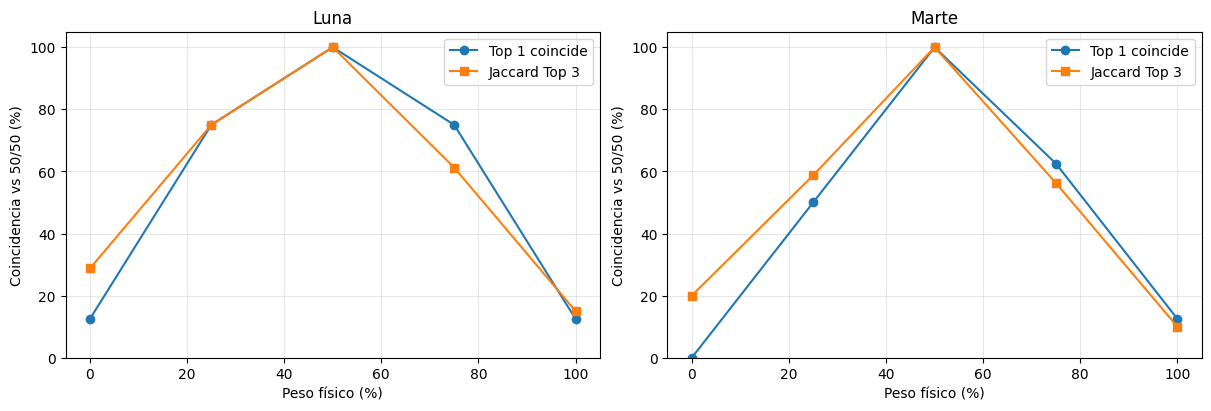

In [36]:
fig,axs=plt.subplots(1,len(planetas),figsize=(6*len(planetas),4),squeeze=False,constrained_layout=True)
for ax,(nombre,d) in zip(axs[0],estabilidad.groupby(level=0)):
    tabla=d.droplevel(0)
    ax.plot(tabla.index*100,tabla['mismo_top1'],marker='o',label='Top 1 coincide')
    ax.plot(tabla.index*100,tabla['jaccard_top3'],marker='s',label='Jaccard Top 3')
    ax.set_title(nombre);ax.set_xlabel('Peso físico (%)');ax.set_ylabel('Coincidencia vs 50/50 (%)')
    ax.set_ylim(0,105);ax.legend();ax.grid(alpha=.3)
plt.show()

## PASO 36 — Mostrar varias correspondencias planetarias en paralelo

Ilustraciones para presentar los resultados del hackathon; mallas referidas a alturas residuales, no fotografías.

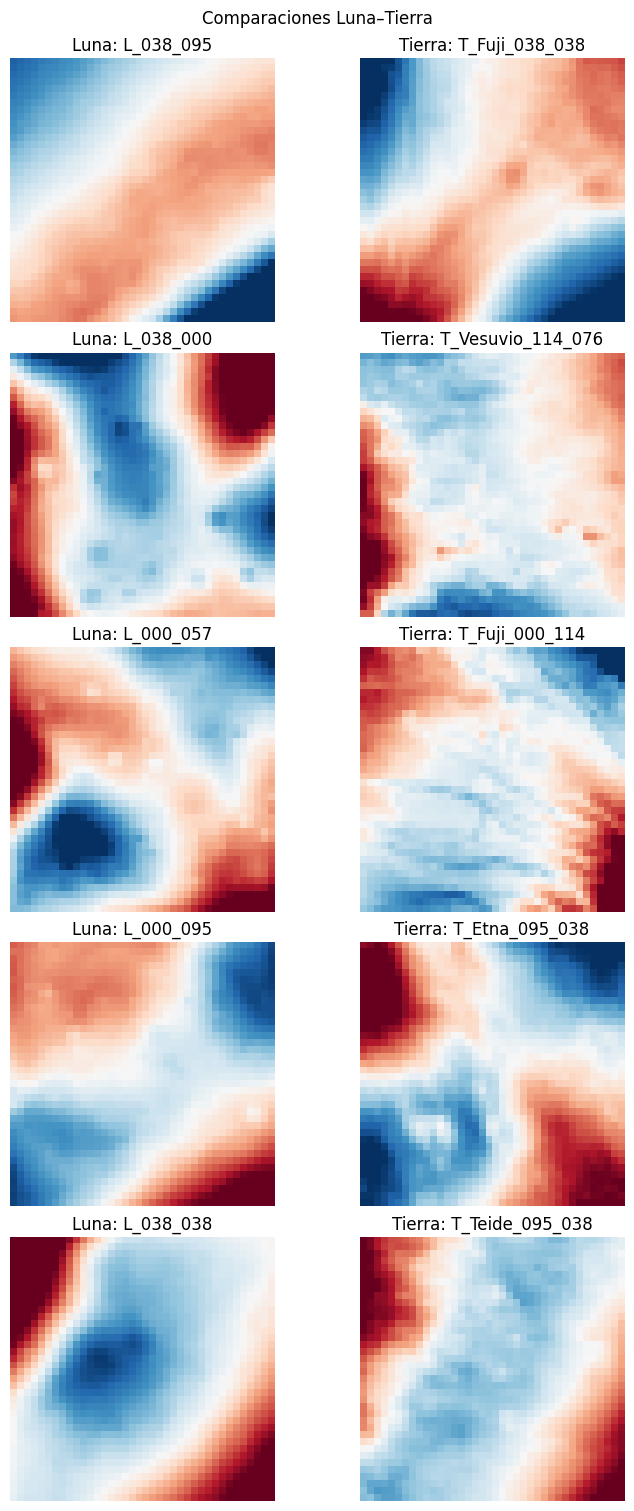

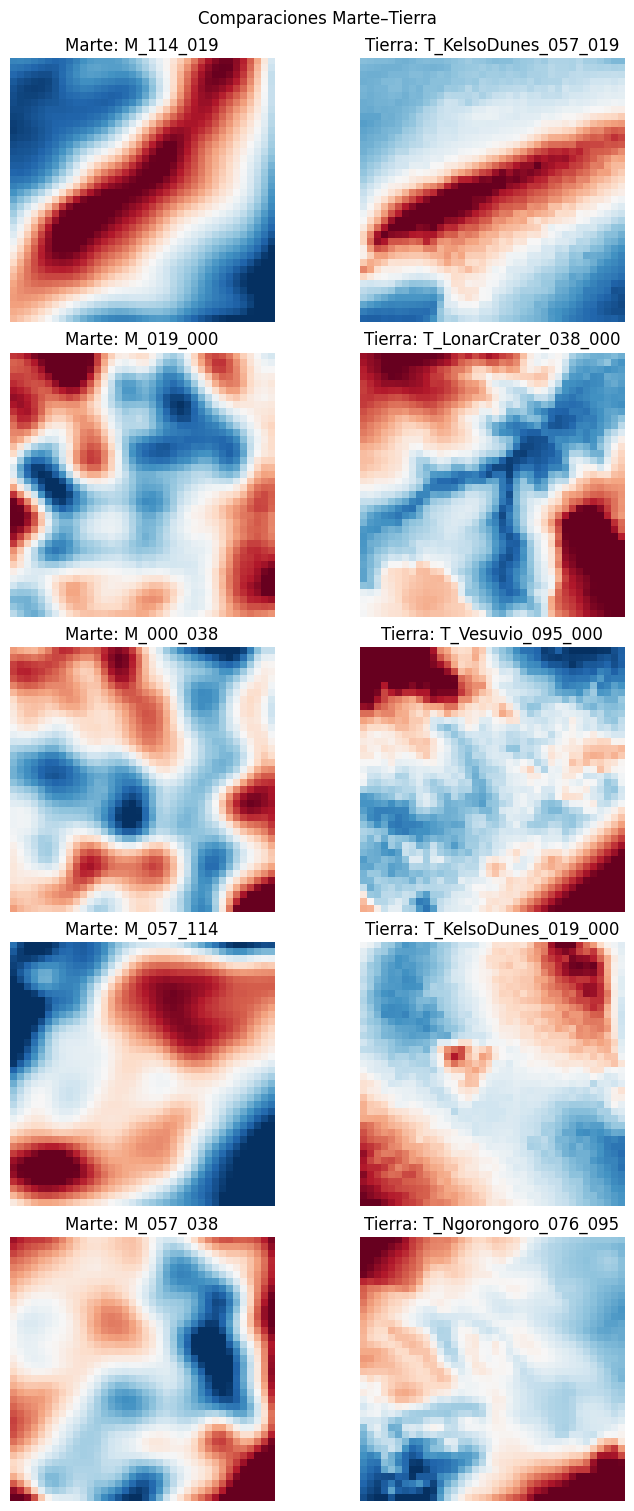

In [37]:
for nombre,t in tablas_planeta.items():
    r=resumen[resumen['cuerpo']==nombre].head(5)
    if r.empty: continue
    fig,axs=plt.subplots(len(r),2,figsize=(7,3*len(r)),squeeze=False,constrained_layout=True)
    for k,(_,reg) in enumerate(r.iterrows()):
        fila_ref=t[t['parche_id']==reg['referencia']].iloc[0]
        tierra=tabla_tierra[tabla_tierra['parche_id']==reg['mejor_tierra']].iloc[0]
        rr=sin_plano(parche(fila_ref));tt=sin_plano(parche(tierra))
        ang=tabla_detalle[(tabla_detalle['cuerpo']==nombre)&(tabla_detalle['referencia']==reg['referencia'])&
                          (tabla_detalle['parche_id']==reg['mejor_tierra'])].iloc[0]['rotacion_grados']
        tt=np.rot90(tt,(int(ang)//90)%4)
        v=np.concatenate([rr[np.isfinite(rr)],tt[np.isfinite(tt)]])
        lim=max(1e-6,np.percentile(np.abs(v),95))
        axs[k,0].imshow(rr,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axs[k,1].imshow(tt,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axs[k,0].set_title(f'{nombre}: {reg["referencia"]}')
        axs[k,1].set_title(f'Tierra: {reg["mejor_tierra"]}')
        for ax in axs[k]:ax.axis('off')
    fig.suptitle(f'Comparaciones {nombre}–Tierra')
    fig.savefig(SALIDAS/f'comparaciones_{nombre.lower()}.png',dpi=150,bbox_inches='tight')
    plt.show()

## PASO 37 — Diagnóstico de estabilidad multiescala en Tierra

Retoma el diagnóstico que antes descubrió mala correlación baja–alta en parches pequeños.

In [38]:
# PASO 37 - DIAGNOSTICO MULTIESCALA A TAMAÑO FISICO SIMILAR
# Cada escala usa una ventana aprox. de 3.04 km, no siempre 38 pixeles.
ejemplo_nombre=next(iter(terrenos_tierra))
p=piramides[ejemplo_nombre]
puntos=[]
for factor,d in p.items():
    n=d.copy();n['nombre']=ejemplo_nombre;n['cuerpo']='Tierra'
    n['crs']=terrenos_tierra[ejemplo_nombre]['crs']
    n.update(caracteristicas_dem(n['H'],n['dx'],n['dy']))
    tam_esc=max(5,round(TAM_PIX/factor))
    salto_esc=max(1,round(SALTO_PIX/factor))
    tpar=crear_parches(n,f'esc{factor}',tam_pix=tam_esc,salto_pix=salto_esc)
    puntos.append((factor,tam_esc,salto_esc,len(tpar)))
print('Factor, pixels/parche, salto, parches válidos:',puntos)
print('Esta celda NO implementa filtrado jerarquico ni mide recuperacion.')


Factor, pixels/parche, salto, parches válidos: [(4, 10, 5, 16), (2, 19, 10, 28), (1, 38, 19, 30)]
Esta celda NO implementa filtrado jerarquico ni mide recuperacion.


## PASO 38 — Medir tiempos computacionales y tamaño de resultados

Métricas de escala actual. Para demostrar velocidad en un catálogo amplio habrá que ejecutar y medir una búsqueda selectiva.

In [39]:
import time
print('Cantidad de DEMs terrestres:',len(terrenos_tierra))
print('Parches terrestres:',len(tabla_tierra))
print('Memoria matrices de elevación (MiB):',round(sum(d['H'].nbytes for d in TERRENOS.values())/(1024**2),2))
print('Candidatos evaluados de forma en última búsqueda:',{nombre:len(d) for nombre,d in metricas.items()})
print('Nota: todavía no se calcula el costo de una búsqueda a escala planetaria completa.')

Cantidad de DEMs terrestres: 50
Parches terrestres: 2579
Memoria matrices de elevación (MiB): 5.63
Candidatos evaluados de forma en última búsqueda: {'Luna': 80, 'Marte': 80}
Nota: todavía no se calcula el costo de una búsqueda a escala planetaria completa.


## PASO 39 — Exportar todos los CSV, mapas y un paquete ZIP

Incluye rankings individuales, pruebas de pesos y GeoTIFF recortados descargados; sin proclamar analogía geológica validada.

In [40]:
import json, zipfile
tabla_tierra.to_csv(SALIDAS/'vectores_tierra.csv',index=False)
for nombre,t in tablas_planeta.items():
    t.to_csv(SALIDAS/f'vectores_{nombre.lower()}.csv',index=False)
for nombre,r in rankings.items():
    r.to_csv(SALIDAS/f'ranking_{nombre.lower()}_tierra.csv',index=False)
resumen.to_csv(SALIDAS/'resumen_multi_planetario.csv',index=False)
tabla_sens.to_csv(SALIDAS/'sensibilidad_pesos.csv',index=False)
tabla_detalle.to_csv(SALIDAS/'rankings_completos.csv',index=False)
config={'resolucion_m':RES_M,'parche_m':TAM_PIX*RES_M,
        'cuerpos_disponibles':list(planetas),'zonas_terrestres':list(terrenos_tierra),
        'normalizacion':'mediana e IQR terrestres','peso_fisico':PESO_FISICO,
        'candidatos_geom':CANDIDATOS_GEOM, 'regiones_solicitadas':len(ZONAS_TERRESTRES), 'regiones_descargadas':len(terrenos_tierra),'validacion':'exploratoria, no geologica'}
(SALIDAS/'configuracion.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
zipname=str(SALIDAS.parent/'Resultados_HackNASA_Tierra_Luna_Marte.zip')
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as zf:
    for f in SALIDAS.iterdir():
        if f.is_file(): zf.write(f,arcname=f.name)
print('ZIP listo:',zipname)
from google.colab import files
files.download(zipname)

ZIP listo: /content/Resultados_HackNASA_Tierra_Luna_Marte.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Al terminar

Puedes descargar el ZIP de resultados generado en el paso 39. Este notebook usa fuentes públicas sin Google Drive, por lo que tus compañeros lo pueden ejecutar con una cuenta de Colab. **La conexión a la red, las cuotas del proveedor y la descarga completa (si DLR no acepta rangos) pueden afectar el tiempo/costo computacional.**

**Precauciones científicas:** Copernicus es DSM (incluye objetos de superficie). Los datums verticales de Tierra/Luna/Marte difieren. Los scores son exploratorios: los mapas y el ranking no garantizan analogía geológica ni seguridad para un rover. La selección de 15 km de relieve por variación de elevación es una heurística, no una muestra representativa.
